# Linux, the Shell and Networking for AI Engineers

> **Who is this for:** anyone who has to log into a server, a cloud VM or a container to deploy, debug or babysit an AI service. You know basic Python; you do not need to be a Linux expert.
>
> **What you will learn:**
> - the Linux **filesystem layout**, **users, groups, permissions** and `sudo`
> - **processes and signals** (`ps`, `top`, `kill`, `nohup`, background jobs) and running an AI API as a **systemd service**, reading its logs with `journalctl`
> - **environment and shell config** (`PATH`, `.bashrc`, environment variables, virtual environments) and **package managers** (`apt`, `pip`, `uv`, `conda`)
> - the **text tools** you use every day (`grep`, `sed`, `awk`, `find`, `xargs`, `jq`, `sort | uniq`, `tail -f`, `less`), **pipes and redirection**, and **safe bash scripting** (`set -euo pipefail`, functions, loops, exit codes, `trap`)
> - finding **slow endpoints and 5xx errors** in an nginx-style access log, first with `awk`, then with pandas
> - **SSH** (keys, config, agent forwarding risks, tunnels, `scp`/`rsync`) and **tmux**
> - **disk and memory** (`df`, `du`, `free`, `ulimit`, the **OOM killer**) and **GPUs on Linux** (`nvidia-smi`, `CUDA_VISIBLE_DEVICES`)
> - **network commands** (`ip`, `ss`, `ping`, `traceroute`, `dig`, `curl`, `nc`, `openssl s_client`), **DNS records** with a toy resolver, **TLS certificates and Let's Encrypt** with an expiry checker
> - **firewalls** (`ufw`, `iptables`, `nftables`), **reverse proxies** (Nginx, Caddy) in front of an AI API, and **cron**
>
> **Prerequisites:** [Operating systems for developers](06_operating_systems_for_developers.ipynb) (processes, memory, the basic shell table), [Computer networks for AI apps](07_computer_networks_for_ai_apps.ipynb) (TCP/IP, HTTP, TLS theory, CIDR). Helpful: [Security for AI applications](08_security_for_ai_applications.ipynb).
>
> **Time needed:** about 3 hours to read and try. The code runs in well under a minute.
>
> **Runs on:** CPU, no API key, no internet. The code only runs **safe, read-only** shell commands inside a temporary folder (via Python `subprocess`). If a command is missing on your machine (for example on Windows or macOS), the cell prints `skipped: needs <tool>` instead of failing. Nothing here changes your system, calls the network or needs `sudo`.

## Explained simply

A cloud GPU server is just a Linux computer that you reach through a text window. To deploy an AI model you need to do the same few things again and again:

1. **Get in** safely (SSH keys, not passwords).
2. **Put files in the right place** with the right owner and permissions.
3. **Start the model server** so it keeps running after you log out and restarts if it crashes (systemd).
4. **Read its logs** and find what is slow or broken (`journalctl`, `grep`, `awk`).
5. **Check the machine**: disk full? memory full? GPU busy? port open?
6. **Put it on the internet** safely: DNS name, TLS certificate, firewall, reverse proxy.

This notebook walks through each step with the commands that do it. The OS notebook explained *how* the operating system works; this one is the **operator's handbook**.

```mermaid
flowchart LR
    U[You, laptop] -- SSH key --> S[Linux VM with GPU]
    S --> D[systemd service: model API on 127.0.0.1:8000]
    C[Users] -- DNS name --> P[Reverse proxy: Nginx or Caddy, TLS on :443]
    P --> D
    F[Firewall: allow 22 from office, 443 from anywhere] --- S
    D --> L[journalctl and access logs]
```

## 0. Setup

We use only the standard library, numpy, pandas and matplotlib. The helper `run()` runs one shell command **inside a temporary folder** with a minimal environment, prints the output, and **skips** the command if the tool is not installed. We never run anything that writes outside that folder.

In [1]:
import os, re, sys, shutil, signal, subprocess, tempfile, time, platform, configparser, textwrap
from pathlib import Path
from datetime import datetime, timedelta, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

WORK = Path(tempfile.mkdtemp(prefix="linux_nb_"))     # every file we create lives here
SAFE_ENV = {"PATH": "/usr/local/bin:/usr/bin:/bin:/usr/sbin:/sbin",
            "LANG": "C", "LC_ALL": "C", "HOME": str(WORK)}
BASH = shutil.which("bash")

def run(cmd, needs=None, timeout=15, show=True, capture=False):
    """Run a safe shell command in WORK. Skip politely if a needed tool is missing.
    Returns the CompletedProcess only when capture=True (keeps notebook output clean)."""
    tools = needs if needs is not None else [cmd.split()[0]]
    missing = [t for t in tools + ["bash"] if shutil.which(t) is None]
    if missing:
        print(f"skipped: needs {', '.join(sorted(set(missing)))}")
        return None
    r = subprocess.run(cmd, shell=True, executable=BASH, cwd=WORK, env=SAFE_ENV,
                       capture_output=True, text=True, timeout=timeout)
    if show:
        print(f"$ {cmd}")
        if r.stdout.strip(): print(r.stdout.rstrip())
        if r.stderr.strip(): print("[stderr]", r.stderr.strip()[:400])
        if r.returncode != 0: print(f"[exit code {r.returncode}]")
    return r if capture else None

print("python", platform.python_version(), "| system:", platform.system(), "| work dir is a temp folder")
print("bash available:", BASH is not None)

python 3.12.3 | system: Linux | work dir is a temp folder
bash available: True


### First commands: who and where am I?

`uname` prints the kernel and machine type, `whoami` your user name, `id` your user and group ids, `echo` prints text, `ls` lists files. These are all read-only.

In [2]:
run("uname -sm")              # kernel name and machine architecture (no hostname, no release)
# `whoami` prints your login name and `id -u` your numeric user id (0 means root).
# We print only whether we are root, so no personal account details end up in the saved notebook.
run('if [ "$(id -u)" -eq 0 ]; then echo "running as root"; else echo "running as a normal (non-root) user"; fi', needs=["id"])
run('echo "hello from bash, in folder $(pwd | sed "s#.*/##")"', needs=["sed"])
run("ls -ld /etc /var/log /tmp", needs=["ls"])


$ uname -sm
Linux x86_64
$ if [ "$(id -u)" -eq 0 ]; then echo "running as root"; else echo "running as a normal (non-root) user"; fi
running as a normal (non-root) user
$ echo "hello from bash, in folder $(pwd | sed "s#.*/##")"
hello from bash, in folder linux_nb_i1jsllzr
$ ls -ld /etc /var/log /tmp
drwxr-xr-x 158 root root    12288 Nov 12 13:17 /etc
drwxrwxrwt  79 root root   139264 Nov 13 18:54 /tmp
drwxrwxr-x  23 root syslog   4096 Nov 13 12:48 /var/log


## 1. The filesystem layout

**What it is:** Linux puts everything in one tree that starts at `/` (the root). The layout follows a standard called the **Filesystem Hierarchy Standard (FHS)**, so the same folders mean the same thing on almost every distribution.

**Simple analogy:** a big office building where every floor has a fixed purpose: reception, storage, archives, staff desks. Once you know the floor plan, you can find things in any branch office.

| Folder | What lives there | AI deployment example |
|---|---|---|
| `/etc` | system-wide **config** files (text) | `/etc/systemd/system/llm-api.service`, `/etc/nginx/`, `/etc/hosts` |
| `/var/log` | **logs** | `/var/log/nginx/access.log`, `/var/log/syslog` |
| `/var/lib` | state data of services | Docker images in `/var/lib/docker` (can fill the disk) |
| `/home/<user>` | each user's files and dotfiles | `~/.bashrc`, `~/.ssh/`, `~/.cache/huggingface` (big model downloads) |
| `/opt` | add-on software installed by hand | `/opt/llm-api/` (your app), `/opt/conda` |
| `/srv` | data served by this machine | `/srv/models/` |
| `/tmp` | temporary files, often wiped on reboot | never keep model weights here |
| `/usr/bin`, `/usr/local/bin` | programs | `python3`, `nvidia-smi` |
| `/proc`, `/sys` | **virtual** files made by the kernel that describe the live system | `/proc/meminfo`, `/proc/<pid>/status` |
| `/dev` | devices | `/dev/nvidia0` (a GPU), `/dev/shm` (shared memory used by PyTorch data loaders) |
| `/mnt`, `/media` | mounted disks | an attached data volume at `/mnt/data` |

**When it matters:** when a disk fills up (usually `/var/lib/docker`, `/var/log` or `~/.cache`), when you write a service file (`/etc/systemd/system`), and when you look for logs.

`/proc` is a nice example of "everything is a file": reading these files is how tools like `free` and `top` get their numbers.

In [3]:
# Read live numbers straight from /proc (Linux only; read-only).
# We print ratios instead of raw sizes so the saved notebook does not describe this particular machine.
meminfo = Path("/proc/meminfo")
if meminfo.exists():
    rows = {k: int(v.split()[0]) for k, v in (line.split(":", 1) for line in meminfo.read_text().splitlines()[:5])}
    print("fields read from /proc/meminfo:", ", ".join(rows))
    print(f"MemAvailable is {rows['MemAvailable'] / rows['MemTotal']:.0%} of MemTotal "
          f"(Linux uses 'free' RAM for the page cache, so MemAvailable is the number to watch, not MemFree)")
    ncpu = sum(1 for line in Path("/proc/cpuinfo").read_text().splitlines() if line.startswith("processor"))
    print("at least one logical CPU found in /proc/cpuinfo:", ncpu >= 1)
else:
    print("skipped: needs a Linux /proc filesystem")


fields read from /proc/meminfo: MemTotal, MemFree, MemAvailable, Buffers, Cached
MemAvailable is 36% of MemTotal (Linux uses 'free' RAM for the page cache, so MemAvailable is the number to watch, not MemFree)
at least one logical CPU found in /proc/cpuinfo: True


## 2. Users, groups, permissions and sudo

**What it is:** every file has an **owner** (a user), a **group**, and three sets of permissions: for the owner (**u**), the group (**g**) and everyone else (**o**). Each set says whether you may **r**ead, **w**rite or e**x**ecute. A **group** is a named set of users who share access, for example `docker` or `video`.

**Simple analogy:** a filing cabinet with three keys: one for the owner, one for the team, one for visitors. Each key opens some drawers (read, write, run) but not others.

**How it works:**
- `ls -l` shows something like `-rwxr-x---  1 llm  ml  2048  run.sh`: type, then `rwx` for owner, `r-x` for group, `---` for others.
- Numbers are a short form: r=4, w=2, x=1, so `rwx`=7, `r-x`=5, `---`=0, and `chmod 750 run.sh` sets the line above.
- `chown llm:ml file` changes the owner and group (needs root).
- **root** (user id 0) can do anything. `sudo <command>` runs one command as root if you are listed in `/etc/sudoers` (edit it only with `visudo`).
- Services should run as their own **system user** with no login shell, for example `sudo useradd --system --no-create-home --shell /usr/sbin/nologin llm`. Then a bug in the model server cannot touch other users' files.

| Common mode | Meaning | Use for |
|---|---|---|
| `600` | owner read/write only | `.env`, API keys, `~/.ssh/id_ed25519` (SSH refuses keys that others can read) |
| `644` | owner writes, everyone reads | normal config, model cards |
| `700` | only owner can enter / run | `~/.ssh` folder, private scripts |
| `755` | everyone can run, only owner edits | scripts and program folders |
| `775` + group | the team can edit | shared `/srv/models` with a `ml` group |

**When not to:** never fix a permission error with `chmod 777` (everyone can write, including an attacker who got in through your web app). Find the right owner or group instead. Adding a user to the `docker` group is almost the same as giving them root, so treat it that way.

In [4]:
def mode_to_rwx(mode: int) -> str:
    """Turn 0o750 into 'rwxr-x---'."""
    out = ""
    for shift in (6, 3, 0):                     # owner, group, others
        bits = (mode >> shift) & 0o7
        out += ("r" if bits & 4 else "-") + ("w" if bits & 2 else "-") + ("x" if bits & 1 else "-")
    return out

def rwx_to_mode(s: str) -> int:
    """Turn 'rw-r-----' into 0o640."""
    val = 0
    for ch, bit in zip(s, [256, 128, 64, 32, 16, 8, 4, 2, 1]):
        if ch != "-": val |= bit
    return val

for m in (0o600, 0o644, 0o750, 0o777):
    print(f"{m:o} -> {mode_to_rwx(m)}")
print("rw-r----- ->", oct(rwx_to_mode("rw-r-----")))

# Now really apply modes to files in our temp folder and look at them with ls / stat
secret = WORK / ".env"; secret.write_text("OPENAI_API_KEY=sk-fake-for-demo\n")
script = WORK / "serve.sh"; script.write_text("#!/usr/bin/env bash\necho serving\n")
os.chmod(secret, 0o600); os.chmod(script, 0o755)
run("ls -l .env serve.sh | awk '{print $1, $NF}'", needs=["ls", "awk"])
run("stat -c '%A %a %n' .env serve.sh", needs=["stat"])
run("./serve.sh", needs=["bash"])

600 -> rw-------
644 -> rw-r--r--
750 -> rwxr-x---
777 -> rwxrwxrwx
rw-r----- -> 0o640
$ ls -l .env serve.sh | awk '{print $1, $NF}'
-rw------- .env
-rwxr-xr-x serve.sh
$ stat -c '%A %a %n' .env serve.sh
-rw------- 600 .env
-rwxr-xr-x 755 serve.sh
$ ./serve.sh
serving


## 3. Processes, signals and background jobs

**What it is:** a **process** is a running program with an id (**PID**). A **signal** is a small message the OS delivers to a process, like "please stop" or "reload your config".

**Simple analogy:** processes are workers; signals are tapping a worker on the shoulder. `SIGTERM` is "please finish and go home", `SIGKILL` is security escorting them out mid-sentence.

| Command | What it does |
|---|---|
| `ps aux` / `ps -ef` | list all processes; `ps aux --sort=-%mem | head` shows memory hogs |
| `pgrep -af uvicorn` | find processes by name |
| `top`, `htop`, `btop` | live view of CPU and memory per process (`htop` is friendlier) |
| `kill <pid>` | send `SIGTERM` (15): ask to stop cleanly |
| `kill -9 <pid>` | send `SIGKILL` (9): cannot be caught; last resort, no cleanup |
| `kill -HUP <pid>` | `SIGHUP` (1): many daemons reload config (Nginx does) |
| `Ctrl+C` | sends `SIGINT` (2) to the foreground program |
| `cmd &` | run in the background of this shell; `jobs`, `fg`, `bg` manage it |
| `nohup cmd > out.log 2>&1 &` | keep running after you log out (ignores `SIGHUP`) |
| `disown` | detach a background job from the shell |

**When to use what:** `nohup` and `&` are fine for a quick one-off training run. For anything that must **survive reboots and crashes**, use a **systemd service** (section 4) or a container. Inside a terminal you want to come back to, use **tmux** (section 11).

**Why signals matter for AI servers:** Kubernetes, Docker and systemd all stop your model server by sending `SIGTERM`, waiting a grace period, then sending `SIGKILL`. A good server catches `SIGTERM`, stops accepting new requests, finishes in-flight generations, then exits. Below, a tiny bash "server" does exactly that with `trap`.

In [5]:
# A toy server that handles SIGTERM gracefully. We start it, then send SIGTERM ourselves.
if BASH:
    server = subprocess.Popen(
        [BASH, "-c", 'trap "echo got SIGTERM: draining 2 in-flight requests; sleep 0.2; echo bye; exit 0" TERM; '
                     'echo "server started, pid $$"; while true; do sleep 0.1; done'],
        stdout=subprocess.PIPE, text=True, env=SAFE_ENV)
    time.sleep(0.5)
    run(f"ps -o pid,stat,comm -p {server.pid}", needs=["ps"])
    server.send_signal(signal.SIGTERM)           # same as: kill <pid>
    out, _ = server.communicate(timeout=5)
    print(out.strip())
    print("exit code:", server.returncode, "(0 = clean shutdown)")
else:
    print("skipped: needs bash")

$ ps -o pid,stat,comm -p 263325
    PID STAT COMMAND
 263325 S    bash


server started, pid 263325
got SIGTERM: draining 2 in-flight requests
bye
exit code: 0 (0 = clean shutdown)


In [6]:
# Background jobs inside a script: '&' starts a job, $! is its PID, 'wait' collects its exit code.
run(r"""bash -c '
sleep 0.3 & pid=$!
echo "started background job with pid $pid"
( exit 3 ) & pid2=$!
wait $pid;  echo "job 1 finished with exit code $?"
wait $pid2; echo "job 2 finished with exit code $?"
'""", needs=["bash", "sleep"])

$ bash -c '
sleep 0.3 & pid=$!
echo "started background job with pid $pid"
( exit 3 ) & pid2=$!
wait $pid;  echo "job 1 finished with exit code $?"
wait $pid2; echo "job 2 finished with exit code $?"
'
started background job with pid 263370
job 1 finished with exit code 0
job 2 finished with exit code 3


## 4. systemd services and journalctl

**What it is:** **systemd** is the program (PID 1) that starts and supervises services on most Linux distributions. You describe a service in a small text file called a **unit file**; `systemctl` controls it and `journalctl` reads its logs.

**Simple analogy:** a building manager who unlocks the doors every morning (start on boot), checks that each shop is open (health), reopens a shop that closed by accident (restart), and keeps a logbook (journal).

**How it works**, for a FastAPI model server:

```ini
# /etc/systemd/system/llm-api.service
[Unit]
Description=LLM inference API
After=network-online.target
Wants=network-online.target

[Service]
User=llm
Group=llm
WorkingDirectory=/opt/llm-api
EnvironmentFile=/etc/llm-api/env          # secrets live here, chmod 600, owned by root
ExecStart=/opt/llm-api/.venv/bin/uvicorn app:app --host 127.0.0.1 --port 8000 --workers 2
Restart=on-failure
RestartSec=5
TimeoutStopSec=60                          # time to finish in-flight requests after SIGTERM
LimitNOFILE=65536                          # many open connections
NoNewPrivileges=true
ProtectSystem=strict
ReadWritePaths=/var/lib/llm-api
PrivateTmp=true

[Install]
WantedBy=multi-user.target
```

```bash
sudo systemctl daemon-reload              # after editing a unit file
sudo systemctl enable --now llm-api       # start now and on every boot
systemctl status llm-api                  # running? last log lines? PID?
sudo systemctl restart llm-api
journalctl -u llm-api -f                  # follow the logs (like tail -f)
journalctl -u llm-api --since "30 min ago" -p err   # only errors, last 30 minutes
journalctl -u llm-api -o json-pretty -n 5           # structured output
systemctl list-units --failed             # what is broken on this box?
systemctl list-timers                     # scheduled jobs (systemd's cron)
```

**When to use it:** any long-running process on a plain VM: model APIs, vector databases, workers, exporters. **When not to:** inside containers (the container runtime or Kubernetes supervises the process instead), or on managed platforms (Cloud Run, Lambda).

The checker below reads a unit file with Python's `configparser` and flags common mistakes. It is a toy, but real teams run similar lint rules in CI. `systemd-analyze security llm-api` is the real tool that scores a unit's hardening.

In [7]:
UNIT = """
[Unit]
Description=LLM inference API
After=network-online.target

[Service]
User=root
WorkingDirectory=/opt/llm-api
Environment=OPENAI_API_KEY=sk-live-oops
ExecStart=/opt/llm-api/.venv/bin/uvicorn app:app --host 0.0.0.0 --port 8000
Restart=no

[Install]
WantedBy=multi-user.target
"""

def lint_unit(text):
    cp = configparser.ConfigParser(strict=False, interpolation=None)
    cp.optionxform = str                               # keep key case (User, not user)
    cp.read_string(text)
    s = cp["Service"] if cp.has_section("Service") else {}
    findings = []
    if s.get("User", "root") == "root":
        findings.append(("high", "runs as root: add User= with a dedicated system user"))
    if s.get("Restart", "no") == "no":
        findings.append(("medium", "no automatic restart: set Restart=on-failure"))
    if re.search(r"(KEY|TOKEN|SECRET|PASSWORD)=", s.get("Environment", ""), re.I):
        findings.append(("high", "secret inline in the unit file: use EnvironmentFile= (chmod 600) or a secret manager"))
    if "0.0.0.0" in s.get("ExecStart", ""):
        findings.append(("medium", "binds to all interfaces: bind 127.0.0.1 behind a reverse proxy"))
    if "NoNewPrivileges" not in s:
        findings.append(("low", "add NoNewPrivileges=true, ProtectSystem=strict, PrivateTmp=true"))
    if not cp.has_option("Install", "WantedBy"):
        findings.append(("medium", "no [Install] WantedBy: will not start on boot"))
    return findings

for sev, msg in lint_unit(UNIT):
    print(f"[{sev:>6}] {msg}")
run("systemctl --version | head -n 1", needs=["systemctl", "head"])   # read-only: just the version

[  high] runs as root: add User= with a dedicated system user
[medium] no automatic restart: set Restart=on-failure
[  high] secret inline in the unit file: use EnvironmentFile= (chmod 600) or a secret manager
[medium] binds to all interfaces: bind 127.0.0.1 behind a reverse proxy
[   low] add NoNewPrivileges=true, ProtectSystem=strict, PrivateTmp=true
$ systemctl --version | head -n 1
systemd 255 (255.4-1ubuntu8.18)


## 5. Environment, PATH and shell config

**What it is:**
- An **environment variable** is a named text value that a process inherits from its parent, like `HF_HOME=/srv/hf-cache` or `CUDA_VISIBLE_DEVICES=0`.
- `PATH` is a special variable: a list of folders, separated by `:`, where the shell looks for programs. `which python` or `command -v python` tells you which one wins.
- **Shell config files** run when a shell starts: `~/.bashrc` for interactive shells, `~/.profile` or `~/.bash_profile` for login shells (for example over SSH). `/etc/environment` is system-wide.

**Simple analogy:** `PATH` is the ordered list of drawers where you look for a tool. If two drawers hold a "python", you take the first one you find.

**How it works:**

```bash
export HF_HOME=/srv/hf-cache          # set for this shell and its children
echo "$HF_HOME"
env | sort | less                     # see everything
export PATH="$HOME/.local/bin:$PATH"  # put your tools first (add to ~/.bashrc to keep it)
source ~/.bashrc                      # re-read config in the current shell
python3 -m venv .venv && source .venv/bin/activate   # a venv just puts .venv/bin first in PATH
```

**Common traps:**
- systemd services and cron jobs **do not read `~/.bashrc`**. Put variables in the unit file (`Environment=` / `EnvironmentFile=`) or the crontab, and use full paths.
- "It works in my terminal but not in the service" is almost always `PATH`, the venv, or a missing variable.
- Do not put secrets in `~/.bashrc`; they leak into every process and into shell history.

The demo below creates a fake `python` in a folder and shows that putting the folder first in `PATH` changes which program runs. Then a few lines of Python do the same search that `which` does.

In [8]:
fake_bin = WORK / "fakebin"; fake_bin.mkdir(exist_ok=True)
fake_py = fake_bin / "python"
fake_py.write_text("#!/usr/bin/env bash\necho 'I am the fake python in fakebin'\n"); os.chmod(fake_py, 0o755)

run('command -v python3; echo "PATH starts with: ${PATH%%:*}"', needs=["bash"])
run('PATH="$PWD/fakebin:$PATH"; command -v python | sed "s#.*/linux_nb_[^/]*#<work>#"; python', needs=["bash", "sed"])

def which(prog, path):
    """What the shell does: walk PATH left to right, return the first executable match."""
    for folder in path.split(":"):
        cand = Path(folder) / prog
        if cand.is_file() and os.access(cand, os.X_OK):
            return str(cand)
    return None

print("which('python', fakebin first) ->", which("python", f"{fake_bin}:{SAFE_ENV['PATH']}").replace(str(WORK), "<work>"))

$ command -v python3; echo "PATH starts with: ${PATH%%:*}"
/usr/bin/python3
PATH starts with: /usr/local/bin
$ PATH="$PWD/fakebin:$PATH"; command -v python | sed "s#.*/linux_nb_[^/]*#<work>#"; python
<work>/fakebin/python
I am the fake python in fakebin
which('python', fakebin first) -> <work>/fakebin/python


## 6. Package managers: apt, pip, uv, conda

**What it is:** a **package manager** downloads software and its dependencies and installs them in the right place. Linux has one for the **system** and Python has its own for **libraries**. Mixing them up is a classic source of breakage.

| Tool | Installs | Typical commands | Notes for AI work |
|---|---|---|---|
| `apt` (Debian, Ubuntu) | system packages | `sudo apt update && sudo apt install -y build-essential git` | drivers, compilers, `nginx`, `ffmpeg` |
| `dnf` / `yum` (RHEL, Fedora, Amazon Linux) | system packages | `sudo dnf install -y git` | same role as apt |
| `pip` | Python packages into the active environment | `pip install -r requirements.txt` | always inside a venv, never `sudo pip` |
| `uv` | fast Python installer, venvs, lock files, Python versions | `uv venv`, `uv pip install -r requirements.txt`, `uv sync` | much faster CI and Docker builds; `uv.lock` pins everything |
| `pipx` / `uv tool` | Python command-line tools in their own envs | `uv tool install ruff` | keeps tools out of project envs |
| `conda` / `mamba` / `micromamba` | Python **and** non-Python libraries (CUDA, MKL) | `conda env create -f environment.yml` | handy when you need specific CUDA or compiled libraries |

**Rules of thumb:**
1. System tools from `apt`/`dnf`; Python libraries in a **venv** (or a container) per project.
2. **Pin versions** (lock file) so the server gets exactly what you tested. See [Security for AI applications](08_security_for_ai_applications.ipynb) for hash pinning and supply-chain checks.
3. PyTorch wheels already include the CUDA runtime libraries; you mostly need a recent **NVIDIA driver** on the host (section 13).
4. On Ubuntu 23.04+ and Debian 12+, `pip install` outside a venv is blocked by design ("externally managed environment"). That is a feature: use a venv.

In [9]:
run("python3 -m pip --version | cut -d' ' -f1-2", needs=["python3", "cut"])
for tool in ["apt", "dnf", "uv", "conda", "pipx"]:
    print(f"{tool:<6}:", "found" if shutil.which(tool) else "not installed here")

$ python3 -m pip --version | cut -d' ' -f1-2
pip 24.0
apt   : found
dnf   : not installed here
uv    : not installed here
conda : not installed here
pipx  : not installed here


## 7. Text tools, pipes and redirection

**What it is:** small programs that each do one job on lines of text, joined with a **pipe** `|` so the output of one becomes the input of the next. Logs, CSVs, configs and command output are all text, so these tools work on all of them.

**Simple analogy:** a kitchen line. One cook washes (grep keeps only some lines), the next chops (cut / awk picks columns), the next counts (sort | uniq -c). Each one is simple; the line is powerful.

| Tool | Job | Example |
|---|---|---|
| `grep` | keep lines that match a pattern (`-i` ignore case, `-v` invert, `-c` count, `-E` regex, `-r` recursive) | `grep -E ' 5[0-9]{2} ' access.log` |
| `sed` | edit text in a stream (substitute, delete lines) | `sed -E 's/token=[^ ]+/token=REDACTED/g'` |
| `awk` | split lines into fields (`$1`, `$2`, `$NF` = last) and compute | `awk '{sum+=$NF} END {print sum/NR}'` |
| `cut`, `tr` | pick columns, translate characters | `cut -d, -f2 data.csv` |
| `sort`, `uniq -c` | sort and count duplicates | `sort | uniq -c | sort -rn | head` |
| `wc -l` | count lines | `wc -l train.jsonl` |
| `head`, `tail -n 50`, `tail -f` | first / last lines, follow a growing file | `tail -f /var/log/nginx/error.log` |
| `less` | scroll a big file (`/` search, `G` end, `q` quit, `+F` follow) | `less +F app.log` |
| `find` | find files by name, size, age | `find ~/.cache -size +1G -mtime +30` |
| `xargs` | turn lines into arguments for another command (use `-0` with `find -print0`) | `find . -name '*.log' -print0 | xargs -0 gzip` |
| `jq` | query and reshape JSON | `jq -r 'select(.level=="ERROR") | .msg' app.jsonl` |
| `tee` | write to a file and keep passing the text on | `python train.py | tee train.log` |

**Redirection:**

| Syntax | Meaning |
|---|---|
| `cmd > out.txt` | stdout to a file (overwrite) |
| `cmd >> out.txt` | append |
| `cmd 2> err.txt` | stderr to a file |
| `cmd > all.log 2>&1` | both stdout and stderr to one file (order matters) |
| `cmd < in.txt` | read stdin from a file |
| `cmd1 | cmd2` | pipe stdout of cmd1 into cmd2 |
| `cmd <<'EOF' ... EOF` | here-doc: inline multi-line input |

First we generate a small **JSON-lines app log** and a folder of logs to practise on.

In [10]:
import json
levels = rng.choice(["INFO", "INFO", "INFO", "WARNING", "ERROR"], size=40)
with open(WORK / "app.jsonl", "w") as f:
    for i, lvl in enumerate(levels):
        msg = {"INFO": "request ok", "WARNING": "slow tokenizer",
               "ERROR": rng.choice(["upstream timeout", "CUDA out of memory", "rate limited by provider"])}[lvl]
        f.write(json.dumps({"ts": f"2026-11-13T10:{i:02d}:00Z", "level": lvl, "msg": str(msg),
                            "request_id": f"req-{1000+i}", "user_token": f"tok_{rng.integers(1e6)}"}) + "\n")
(WORK / "logs").mkdir(exist_ok=True)
for name, n in [("train.log", 12), ("eval.log", 5), ("old.log", 3)]:
    (WORK / "logs" / name).write_text("".join(f"step {i} loss {1/(i+1):.3f}\n" for i in range(n)))

run("head -n 2 app.jsonl", needs=["head"])
run("grep -c '\"ERROR\"' app.jsonl", needs=["grep"])
run("grep '\"ERROR\"' app.jsonl | jq -r .msg | sort | uniq -c | sort -rn", needs=["grep", "jq", "sort", "uniq"])

$ head -n 2 app.jsonl
{"ts": "2026-11-13T10:00:00Z", "level": "INFO", "msg": "request ok", "request_id": "req-1000", "user_token": "tok_758087"}
{"ts": "2026-11-13T10:01:00Z", "level": "WARNING", "msg": "slow tokenizer", "request_id": "req-1001", "user_token": "tok_354525"}
$ grep -c '"ERROR"' app.jsonl
8
$ grep '"ERROR"' app.jsonl | jq -r .msg | sort | uniq -c | sort -rn
      4 CUDA out of memory
      2 upstream timeout
      2 rate limited by provider


In [11]:
# sed: redact tokens before sharing a log; find + xargs: count lines in every .log file
run(r"""head -n 1 app.jsonl | sed -E 's/"tok_[0-9]+"/"REDACTED"/'""", needs=["head", "sed"])
run("find logs -name '*.log' -print0 | sort -z | xargs -0 wc -l", needs=["find", "xargs", "wc", "sort"])
# redirection: stdout and stderr into separate files, then into one file
run("ls logs missing_dir > out.txt 2> err.txt; echo \"stdout lines: $(wc -l < out.txt), stderr: $(cat err.txt)\"", needs=["ls", "wc", "cat"])
run("ls logs missing_dir > both.txt 2>&1; wc -l < both.txt", needs=["ls", "wc"])
# a here-doc feeding awk
run("""awk -F, 'NR>1 {s+=$2} END {print "total GPU hours:", s}' <<'EOF'
job,gpu_hours
finetune,12.5
eval,1.5
embed,3
EOF""", needs=["awk"])

$ head -n 1 app.jsonl | sed -E 's/"tok_[0-9]+"/"REDACTED"/'
{"ts": "2026-11-13T10:00:00Z", "level": "INFO", "msg": "request ok", "request_id": "req-1000", "user_token": "REDACTED"}
$ find logs -name '*.log' -print0 | sort -z | xargs -0 wc -l
  5 logs/eval.log
  3 logs/old.log
 12 logs/train.log
 20 total
$ ls logs missing_dir > out.txt 2> err.txt; echo "stdout lines: $(wc -l < out.txt), stderr: $(cat err.txt)"
stdout lines: 4, stderr: ls: cannot access 'missing_dir': No such file or directory
$ ls logs missing_dir > both.txt 2>&1; wc -l < both.txt
5
$ awk -F, 'NR>1 {s+=$2} END {print "total GPU hours:", s}' <<'EOF'
job,gpu_hours
finetune,12.5
eval,1.5
embed,3
EOF
total GPU hours: 17


## 8. Hands-on: find slow endpoints and 5xx errors in an access log

**The situation:** users say "the chatbot is slow and sometimes errors". Your API sits behind Nginx, which writes one line per request. We generate a realistic fake log (one hour, documentation IP addresses from `203.0.113.0/24`) with an incident hidden in it, then find it two ways:

1. with `awk`, `sort` and `uniq` directly on the server (no Python needed, works over SSH on any box);
2. with pandas, for percentiles and a quick chart.

The log format is Nginx's "combined" format plus the request time in seconds at the end (Nginx's `$request_time`), which is a common custom setup:

```
203.0.113.7 - - [13/Nov/2026:10:31:02 +0000] "POST /v1/chat HTTP/1.1" 503 162 "-" "python-httpx/0.27" 30.012
```

In [12]:
endpoints = {               # endpoint: (share of traffic, typical seconds, method)
    "/v1/chat":        (0.45, 1.8, "POST"),
    "/v1/embeddings":  (0.25, 0.08, "POST"),
    "/v1/rerank":      (0.10, 0.25, "POST"),
    "/v1/images":      (0.05, 6.0, "POST"),
    "/health":         (0.15, 0.002, "GET"),
}
names = list(endpoints); probs = [endpoints[e][0] for e in names]
start = datetime(2026, 11, 13, 10, 0, 0, tzinfo=timezone.utc)
lines = []
for i in range(6000):
    t = start + timedelta(seconds=float(rng.uniform(0, 3600)))
    ep = rng.choice(names, p=probs); share, base, method = endpoints[ep]
    rt = float(rng.lognormal(np.log(base), 0.4))
    status = int(rng.choice([200, 429, 400], p=[0.982, 0.009, 0.009]))   # mostly fine, a few client errors
    incident = ep == "/v1/chat" and 30 <= t.minute < 36        # the hidden incident: provider outage
    if incident and rng.random() < 0.6:
        status, rt = int(rng.choice([502, 503, 504])), float(rng.uniform(25, 30.5))
    if rng.random() < 0.002:
        status = 500
    ip = f"203.0.113.{int(rng.integers(1, 60))}"
    size = int(rng.integers(150, 4000))
    lines.append((t, f'{ip} - - [{t:%d/%b/%Y:%H:%M:%S} +0000] "{method} {ep} HTTP/1.1" {status} {size} "-" "python-httpx/0.27" {rt:.3f}'))
lines.sort()
(WORK / "access.log").write_text("\n".join(l for _, l in lines) + "\n")
run("wc -l access.log && tail -n 2 access.log", needs=["wc", "tail"])

$ wc -l access.log && tail -n 2 access.log
6000 access.log
203.0.113.55 - - [13/Nov/2026:10:59:59 +0000] "POST /v1/chat HTTP/1.1" 200 3825 "-" "python-httpx/0.27" 1.401
203.0.113.18 - - [13/Nov/2026:10:59:59 +0000] "POST /v1/chat HTTP/1.1" 200 3680 "-" "python-httpx/0.27" 3.030


With `awk` the fields are split on spaces: `$1` is the client IP, `$7` the path, `$9` the status code, `$NF` (the last field) the request time.

In [13]:
print("# 1) status code counts")
run("awk '{print $9}' access.log | sort | uniq -c | sort -rn", needs=["awk", "sort", "uniq"])
print("\n# 2) 5xx errors per endpoint")
run("awk '$9 >= 500 {c[$7]++} END {for (k in c) print c[k], k}' access.log | sort -rn", needs=["awk", "sort"])
print("\n# 3) average and max request time per endpoint")
run("""awk '{s[$7]+=$NF; n[$7]++; if ($NF>m[$7]) m[$7]=$NF}
     END {for (k in s) printf "%-16s n=%5d  avg=%7.3fs  max=%7.3fs\\n", k, n[k], s[k]/n[k], m[k]}' access.log | sort""",
    needs=["awk", "sort"])
print("\n# 4) which minutes had the most 5xx? (characters 14-18 of $4 are HH:MM)")
run("awk '$9 >= 500 {print substr($4, 14, 5)}' access.log | sort | uniq -c | sort -rn | head -n 5", needs=["awk", "sort", "uniq", "head"])

# 1) status code counts
$ awk '{print $9}' access.log | sort | uniq -c | sort -rn
   5673 200
     78 502
     66 504
     62 503
     56 429
     52 400
     13 500

# 2) 5xx errors per endpoint
$ awk '$9 >= 500 {c[$7]++} END {for (k in c) print c[k], k}' access.log | sort -rn
214 /v1/chat
2 /v1/rerank
2 /v1/images
1 /v1/embeddings

# 3) average and max request time per endpoint
$ awk '{s[$7]+=$NF; n[$7]++; if ($NF>m[$7]) m[$7]=$NF}
     END {for (k in s) printf "%-16s n=%5d  avg=%7.3fs  max=%7.3fs\n", k, n[k], s[k]/n[k], m[k]}' access.log | sort
/health          n=  847  avg=  0.002s  max=  0.006s
/v1/chat         n= 2718  avg=  3.910s  max= 30.457s
/v1/embeddings   n= 1501  avg=  0.085s  max=  0.296s
/v1/images       n=  333  avg=  6.502s  max= 18.390s
/v1/rerank       n=  601  avg=  0.274s  max=  0.816s

# 4) which minutes had the most 5xx? (characters 14-18 of $4 are HH:MM)
$ awk '$9 >= 500 {print substr($4, 14, 5)}' access.log | sort | uniq -c | sort -rn | head -n 5
     39 10:30

The awk view already tells the story: `/v1/chat` has many 502/503/504 errors, the maximum time is around 30 seconds (a timeout), and they cluster around 10:30-10:35. Now the same log in pandas, where percentiles are easy. **Percentiles** matter more than averages for latency: the p95 is the time that 95% of requests beat.

In [14]:
LOG_RE = re.compile(r'(?P<ip>\S+) \S+ \S+ \[(?P<time>[^\]]+)\] "(?P<method>\S+) (?P<path>\S+) \S+" '
                    r'(?P<status>\d{3}) (?P<bytes>\d+) "[^"]*" "[^"]*" (?P<rt>[\d.]+)')
rows = [m.groupdict() for m in map(LOG_RE.match, (WORK / "access.log").read_text().splitlines()) if m]
df = pd.DataFrame(rows)
df["time"] = pd.to_datetime(df["time"], format="%d/%b/%Y:%H:%M:%S %z")
df["status"] = df["status"].astype(int); df["rt"] = df["rt"].astype(float)
df["is_5xx"] = df["status"] >= 500

summary = (df.groupby("path")
             .agg(requests=("rt", "size"),
                  p50_s=("rt", lambda s: s.quantile(0.50)),
                  p95_s=("rt", lambda s: s.quantile(0.95)),
                  p99_s=("rt", lambda s: s.quantile(0.99)),
                  err_5xx_pct=("is_5xx", lambda s: 100 * s.mean()))
             .round(3).sort_values("p95_s", ascending=False))
print(summary)

                requests  p50_s   p95_s   p99_s  err_5xx_pct
path                                                        
/v1/chat            2718  1.869  26.859  29.755        7.873
/v1/images           333  6.141  11.336  14.325        0.601
/v1/rerank           601  0.252   0.488   0.586        0.333
/v1/embeddings      1501  0.079   0.150   0.196        0.067
/health              847  0.002   0.004   0.005        0.000


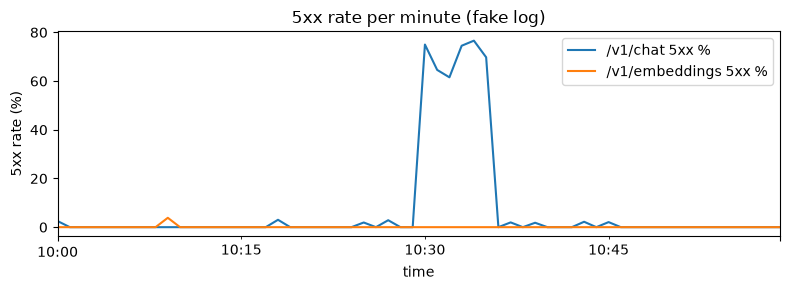

incident window for /v1/chat: 10:30 to 10:35


In [15]:
per_min = df.set_index("time").groupby([pd.Grouper(freq="1min"), "path"])["is_5xx"].mean().unstack().fillna(0) * 100
fig, ax = plt.subplots(figsize=(8, 3))
per_min["/v1/chat"].plot(ax=ax, label="/v1/chat 5xx %")
per_min["/v1/embeddings"].plot(ax=ax, label="/v1/embeddings 5xx %")
ax.set_ylabel("5xx rate (%)"); ax.set_title("5xx rate per minute (fake log)"); ax.legend()
plt.tight_layout(); plt.show()
bad = per_min["/v1/chat"][per_min["/v1/chat"] > 5]
print("incident window for /v1/chat:", bad.index.min().strftime("%H:%M"), "to", bad.index.max().strftime("%H:%M"))

**What we learned:** the 5xx errors are concentrated on one endpoint and one time window, and their request time is about 30 seconds. That pattern (502/504 after a fixed time) usually means the **upstream** (the LLM provider or the model server) stopped answering and Nginx gave up after its `proxy_read_timeout`. Next steps would be the model server's own logs (`journalctl -u llm-api --since "10:29" --until "10:37"`) and the provider's status page. The [observability notebook](../15_MLOps/16_observability_hands_on.ipynb) shows how to turn these numbers into SLOs and alerts instead of grepping by hand.

## 9. Bash scripting that fails safely

**What it is:** a bash script is a text file of shell commands. By default bash **keeps going after errors**, which is dangerous in deploy scripts: a failed `cd` followed by `rm -rf *` deletes the wrong folder.

**Simple analogy:** a recipe robot that, by default, keeps cooking even after it drops the eggs. `set -euo pipefail` tells it to stop and shout as soon as anything goes wrong.

| Setting | Meaning |
|---|---|
| `set -e` | exit when a command fails (non-zero exit code) |
| `set -u` | treat an unset variable as an error (catches typos like `$MODLE_DIR`) |
| `set -o pipefail` | a pipeline fails if **any** part fails, not only the last command |
| `trap 'cleanup' EXIT` | always run cleanup code, even on error |
| `"$var"` | always quote variables, so spaces in names do not split them |
| `exit 0` / `exit 1` | 0 means success; anything else means failure (CI and systemd read this) |

A script template:

```bash
#!/usr/bin/env bash
set -euo pipefail
IFS=$'\n\t'

MODEL_DIR="${MODEL_DIR:-/srv/models}"     # default if not set
log() { printf '%s %s\n' "$(date -u +%FT%TZ)" "$*" >&2; }
cleanup() { rm -rf "${TMP_DIR:-}"; }
trap cleanup EXIT

TMP_DIR="$(mktemp -d)"
for f in "$MODEL_DIR"/*.safetensors; do
  log "checking $f"
  sha256sum "$f" >> "$TMP_DIR/hashes.txt"
done
log "done"
```

Let us prove the difference on real scripts. Without `pipefail`, a failing first command in a pipe is hidden. Without `-u`, a typo in a variable name silently becomes an empty string.

In [16]:
(WORK / "unsafe.sh").write_text("""#!/usr/bin/env bash
false | sort                       # first command fails, but the pipe "succeeds"
echo "unsafe: kept going after a failed pipe"
echo "unsafe: model dir is '$MODLE_DIR' (typo, empty)"
""")
(WORK / "safe.sh").write_text("""#!/usr/bin/env bash
set -euo pipefail
trap 'echo "safe: cleanup ran (exit code $?)"' EXIT
false | sort
echo "safe: this line never runs"
""")
run("bash unsafe.sh; echo \"exit code: $?\"", needs=["bash", "sort"])
run("bash safe.sh; echo \"exit code: $?\"", needs=["bash", "sort"])

$ bash unsafe.sh; echo "exit code: $?"
unsafe: kept going after a failed pipe
unsafe: model dir is '' (typo, empty)
exit code: 0
$ bash safe.sh; echo "exit code: $?"
safe: cleanup ran (exit code 1)
exit code: 1


In [17]:
# Functions, loops, arguments and exit codes: a tiny "pre-deploy check" script
(WORK / "check.sh").write_text("""#!/usr/bin/env bash
set -euo pipefail
fail=0
check_file() {                        # $1 = path, $2 = wanted mode
  local path="$1" want="$2" have
  if [[ ! -e "$path" ]]; then echo "MISSING  $path"; return 1; fi
  have="$(stat -c %a "$path")"
  if [[ "$have" != "$want" ]]; then echo "BADMODE  $path is $have, want $want"; return 1; fi
  echo "OK       $path ($have)"
}
for spec in ".env:600" "serve.sh:755" "model.safetensors:644"; do
  check_file "${spec%%:*}" "${spec##*:}" || fail=$((fail + 1))
done
echo "problems: $fail"
exit "$fail"                          # non-zero tells CI / systemd that the check failed
""")
run("bash check.sh; echo \"exit code: $?\"", needs=["bash", "stat"])

$ bash check.sh; echo "exit code: $?"
OK       .env (600)
OK       serve.sh (755)
MISSING  model.safetensors
problems: 1
exit code: 1


## 10. SSH: keys, config, agent forwarding, tunnels, scp and rsync

**What it is:** **SSH** (Secure Shell) gives you an encrypted terminal on a remote machine. You prove who you are with a **key pair**: a **private key** that never leaves your laptop and a **public key** you copy to the server's `~/.ssh/authorized_keys`.

**Simple analogy:** the public key is a padlock you hand out; only your private key opens it. Giving someone the padlock is harmless.

**How it works:**

```bash
ssh-keygen -t ed25519 -C "you@laptop"            # make a key pair (ed25519 is the modern default)
ssh-copy-id -i ~/.ssh/id_ed25519.pub ubuntu@gpu-box   # install the public key on the server
ssh ubuntu@gpu-box                                # log in
scp model.safetensors gpu-box:/srv/models/        # copy one file
rsync -avP --partial ./checkpoints/ gpu-box:/srv/ckpt/   # copy a folder, resumable, only changes
ssh -L 8888:localhost:8888 gpu-box                # local port forward: open Jupyter on the server at http://localhost:8888
ssh -L 6006:localhost:6006 gpu-box                # same for TensorBoard
ssh -R 9000:localhost:3000 gpu-box                # remote forward: expose your laptop's port 3000 on the server
ssh -D 1080 gpu-box                               # dynamic SOCKS proxy through the server
ssh -J bastion.example.com ubuntu@10.0.2.15       # jump through a bastion host to a private subnet
```

A `~/.ssh/config` saves typing:

```
Host gpu-box
    HostName 198.51.100.20
    User ubuntu
    IdentityFile ~/.ssh/id_ed25519
    IdentitiesOnly yes

Host private-trainer
    HostName 10.0.2.15
    User ubuntu
    ProxyJump bastion.example.com
```

**Agent forwarding risk:** `ssh -A` (or `ForwardAgent yes`) lets the remote machine **use** your local keys while you are connected. Anyone with root on that machine can then log in **as you** to other servers. Prefer `ProxyJump` (`-J`), which never exposes your agent to the middle host.

**Server hardening (in `/etc/ssh/sshd_config`):** `PasswordAuthentication no`, `PermitRootLogin no`, keys only, restrict port 22 to known IPs with the firewall, and consider **no open SSH at all**: cloud services such as AWS Systems Manager Session Manager, Azure Bastion and Google Cloud IAP TCP forwarding give shell access through your cloud identity.

**VPNs and mesh networks:** instead of exposing SSH or internal dashboards, teams often join machines to a private network: **WireGuard** (a fast, simple VPN protocol built into Linux), or products built on it such as **Tailscale** (identity-based mesh VPN), plus cloud VPN gateways. Then `ssh gpu-box` works over a private address and port 22 stays closed to the internet.

**When not to use SSH:** for routine deploys. If you SSH in to change things by hand, the server drifts away from what is in Git. Use it to **debug**; deploy with CI/CD, containers and infrastructure as code.

In [18]:
# Generate a throwaway key pair in the temp folder (local only, no network) and look at it.
if shutil.which("ssh-keygen"):
    run('ssh-keygen -q -t ed25519 -N "" -C "demo-key" -f demo_ed25519 && ls -l demo_ed25519* | awk \'{print $1, $NF}\'',
        needs=["ssh-keygen", "ls", "awk"])
    run("ssh-keygen -lf demo_ed25519.pub | awk '{print $1, $3, $4}'", needs=["ssh-keygen", "awk"])
    print("note: the private key is 600 (owner only); the .pub file is safe to share")
    for p in WORK.glob("demo_ed25519*"): p.unlink()
else:
    print("skipped: needs ssh-keygen")

$ ssh-keygen -q -t ed25519 -N "" -C "demo-key" -f demo_ed25519 && ls -l demo_ed25519* | awk '{print $1, $NF}'
-rw------- demo_ed25519
-rw-r--r-- demo_ed25519.pub
$ ssh-keygen -lf demo_ed25519.pub | awk '{print $1, $3, $4}'
256 demo-key (ED25519)
note: the private key is 600 (owner only); the .pub file is safe to share


In [19]:
SSH_CONFIG = """
Host *
    ForwardAgent yes
    StrictHostKeyChecking no

Host gpu-box
    HostName 198.51.100.20
    User root
    PasswordAuthentication yes

Host private-trainer
    HostName 10.0.2.15
    ProxyJump bastion.example.com
"""
RISKS = {
    ("forwardagent", "yes"): "agent forwarding: a root user on the remote can reuse your keys; prefer ProxyJump",
    ("stricthostkeychecking", "no"): "host keys not checked: open to man-in-the-middle attacks",
    ("user", "root"): "logging in as root: use a normal user plus sudo",
    ("passwordauthentication", "yes"): "passwords allowed: use keys only",
}
host = None
for line in SSH_CONFIG.splitlines():
    parts = line.split()
    if len(parts) < 2: continue
    key, val = parts[0].lower(), parts[1].lower()
    if key == "host": host = parts[1]; continue
    if (key, val) in RISKS:
        print(f"Host {host:<16} {parts[0]} {parts[1]:<4} -> {RISKS[(key, val)]}")

Host *                ForwardAgent yes  -> agent forwarding: a root user on the remote can reuse your keys; prefer ProxyJump
Host *                StrictHostKeyChecking no   -> host keys not checked: open to man-in-the-middle attacks
Host gpu-box          User root -> logging in as root: use a normal user plus sudo
Host gpu-box          PasswordAuthentication yes  -> passwords allowed: use keys only


## 11. tmux and screen: terminals that survive disconnects

**What it is:** **tmux** (and the older **screen**) keeps a terminal session running on the server even if your SSH connection drops. You can detach, go home, and reattach later to the same training run.

**Simple analogy:** leaving your desk with all your papers spread out, instead of packing everything away every time you go for coffee.

| Action | tmux | screen |
|---|---|---|
| start a named session | `tmux new -s train` | `screen -S train` |
| detach (leave it running) | `Ctrl+b` then `d` | `Ctrl+a` then `d` |
| list sessions | `tmux ls` | `screen -ls` |
| reattach | `tmux attach -t train` | `screen -r train` |
| split pane | `Ctrl+b %` (side by side), `Ctrl+b "` (top/bottom) | `Ctrl+a |` |
| scroll back | `Ctrl+b [` then arrows, `q` to quit | `Ctrl+a Esc` |

**When to use it:** interactive work on a remote GPU box: a training run plus `nvidia-smi` in a second pane plus `tail -f` in a third. **When not to:** production services; those belong in systemd or a container, not in someone's tmux session.

In [20]:
run("tmux -V", needs=["tmux"])
run("screen -v | head -n 1", needs=["screen", "head"])

skipped: needs tmux
skipped: needs screen


## 12. Disk, memory, limits and the OOM killer

**What it is:**
- `df -h` shows free space per **filesystem**; `du -sh <dir>` shows how much a folder uses; `ncdu` is an interactive version.
- `free -h` shows RAM and **swap** (disk space used as slow extra memory). Look at the **available** column, not "free": Linux uses spare RAM as a file cache and gives it back when needed.
- `ulimit -n` shows the per-process **limit** on open files (each network connection is a file). A busy API can hit the default (often 1024) and fail with "Too many open files". Raise it with `LimitNOFILE=` in the systemd unit.
- The **OOM killer** ("out of memory") is the kernel's last resort: when RAM runs out, it picks the process with the highest **OOM score** (mostly: the one using the most memory) and kills it with `SIGKILL`. Your model server disappears with no Python traceback. `dmesg -T | grep -i oom` or `journalctl -k | grep -i oom` shows that it happened.

**Simple analogy:** a lifeboat that is too heavy. The captain throws the heaviest bag overboard first, without asking.

**AI-specific traps:**
- `~/.cache/huggingface`, `/var/lib/docker` and old checkpoints fill disks fast: `du -sh ~/.cache/* | sort -h`.
- Docker gives containers a 64 MB `/dev/shm` by default; PyTorch `DataLoader` workers use shared memory and crash. Use `--shm-size=8g` or `--ipc=host`.
- In containers and Kubernetes, the memory **limit** of the container (a **cgroup** limit) triggers the OOM killer, even if the host has free RAM. Kubernetes reports this as `OOMKilled`.
- GPU memory is separate from RAM: "CUDA out of memory" is a Python exception, not the OOM killer.

**When the box is slow but nothing is obviously wrong**, these read-only tools show where the time goes:

| Tool | Shows | Look for |
|---|---|---|
| `uptime`, `top` | load average vs number of CPUs | load far above CPU count = queueing |
| `vmstat 1` | CPU, memory, swap, run queue every second | `si`/`so` (swapping), high `wa` (waiting on disk) |
| `iostat -xz 1` (sysstat package) | per-disk utilisation and latency | `%util` near 100, high `await` (slow model loading from disk) |
| `sar` | history of the same counters | what happened at 3 am |
| `lsof -p <pid>` | open files and sockets of a process | file-descriptor leaks, "Too many open files" |
| `strace -p <pid> -f -e trace=network` | system calls a process makes | a process stuck on a network call or a missing file |
| `perf top`, `perf record` | CPU hot spots in native code | where CPU time goes (flame graphs) |

In [21]:
# Disk and memory checks. We print percentages only, so the saved notebook does not describe this machine.
run("df -h . | tail -n 1 | awk '{print \"disk use% of this filesystem:\", $5}'", needs=["df", "tail", "awk"])
run("du -sh logs app.jsonl access.log", needs=["du"])      # sizes of the small files this notebook created
run("free | awk '/^Mem:/ {printf \"memory in use: %.0f%%\\n\", ($2-$7)/$2*100}'", needs=["free", "awk"])
run("ulimit -n", needs=["bash"])                          # max open files for this shell
import resource
soft, hard = resource.getrlimit(resource.RLIMIT_NOFILE)
print("Python can see its open-file limit (soft <= hard):", soft <= hard)
p = Path("/proc/self/oom_score")
print("this process has an OOM score file:", p.exists())


$ df -h . | tail -n 1 | awk '{print "disk use% of this filesystem:", $5}'
disk use% of this filesystem: 73%
$ du -sh logs app.jsonl access.log
16K	logs
8.0K	app.jsonl
652K	access.log
$ free | awk '/^Mem:/ {printf "memory in use: %.0f%%\n", ($2-$7)/$2*100}'
memory in use: 65%
$ ulimit -n
1048576
Python can see its open-file limit (soft <= hard): True
this process has an OOM score file: True


In [22]:
# A toy OOM killer: when used memory exceeds RAM, kill the process with the highest score.
# Real kernel score is roughly (memory share * 1000) + oom_score_adj (-1000 .. +1000).
RAM_GB = 64
procs = pd.DataFrame([
    ("sshd",            0.05, -1000),   # protected
    ("postgres",        6.0,   -200),
    ("vector-db",      10.0,      0),
    ("llm-api (vLLM)", 38.0,      0),
    ("jupyter kernel", 14.0,    300),   # a notebook someone left running
], columns=["process", "rss_gb", "oom_score_adj"])

def oom_round(df):
    df = df.copy()
    df["score"] = (df["rss_gb"] / RAM_GB * 1000 + df["oom_score_adj"]).clip(lower=0).round()
    return df.sort_values("score", ascending=False)

used = procs["rss_gb"].sum()
print(f"memory used {used:.1f} GB of {RAM_GB} GB")
while used > RAM_GB:
    scored = oom_round(procs)
    victim = scored.iloc[0]
    print(f"OOM! killing '{victim.process}' (score {victim.score:.0f}, {victim.rss_gb} GB)")
    procs = procs[procs.process != victim.process]; used = procs["rss_gb"].sum()
print(oom_round(procs).to_string(index=False))
print("lesson: set oom_score_adj (systemd: OOMScoreAdjust=) and memory limits so the right thing dies")

memory used 68.0 GB of 64 GB
OOM! killing 'llm-api (vLLM)' (score 594, 38.0 GB)
       process  rss_gb  oom_score_adj  score
jupyter kernel   14.00            300  519.0
     vector-db   10.00              0  156.0
      postgres    6.00           -200    0.0
          sshd    0.05          -1000    0.0
lesson: set oom_score_adj (systemd: OOMScoreAdjust=) and memory limits so the right thing dies


## 13. GPUs on Linux: nvidia-smi and CUDA visibility

**What it is:** NVIDIA GPUs need a kernel **driver** on the host. `nvidia-smi` (System Management Interface) shows each GPU's memory, utilisation, temperature and the processes using it. The **CUDA toolkit** (compiler, libraries) is separate; PyTorch wheels bring their own CUDA runtime, but they need a driver that is new enough.

**Simple analogy:** the driver is the engine; CUDA libraries are the gearbox that each car (framework) brings along. An old engine cannot drive a new gearbox.

```bash
nvidia-smi                                   # overview table
watch -n 1 nvidia-smi                        # refresh every second
nvidia-smi --query-gpu=index,name,utilization.gpu,memory.used,memory.total --format=csv
nvidia-smi --query-compute-apps=pid,process_name,used_memory --format=csv
nvidia-smi topo -m                           # how GPUs connect (NVLink vs PCIe)
nvtop                                        # htop-like view for GPUs
CUDA_VISIBLE_DEVICES=1 python serve.py       # this process sees only physical GPU 1 (as cuda:0)
CUDA_VISIBLE_DEVICES=2,3 torchrun --nproc_per_node=2 train.py
CUDA_DEVICE_ORDER=PCI_BUS_ID                 # number GPUs like nvidia-smi does (default is "fastest first")
```

**`CUDA_VISIBLE_DEVICES`** hides GPUs from a process and **renumbers** the visible ones from 0. It is how you share one 8-GPU box between jobs, and it is what Kubernetes and Slurm set for you. An empty value (`CUDA_VISIBLE_DEVICES=`) hides all GPUs, useful to force CPU mode in tests.

**When things go wrong:** "no CUDA GPUs are available" usually means the driver is missing, the container was started without GPU access (`docker run --gpus all` with the NVIDIA Container Toolkit), or `CUDA_VISIBLE_DEVICES` is empty. "CUDA out of memory" means another process holds the memory; check `nvidia-smi --query-compute-apps`. Cluster-level GPU operations (GPU Operator, MIG, DCGM exporter) are covered in the [Kubernetes notebook](../17_Docker/kubernetes/01_kubernetes.ipynb).

In [23]:
run("nvidia-smi --query-gpu=index,name,utilization.gpu,memory.used,memory.total --format=csv", needs=["nvidia-smi"])

def visible_map(cuda_visible_devices, n_physical):
    """Return {logical cuda:i -> physical GPU} the way CUDA applies CUDA_VISIBLE_DEVICES."""
    if cuda_visible_devices is None:
        return {f"cuda:{i}": i for i in range(n_physical)}
    out = {}
    for tok in [t.strip() for t in cuda_visible_devices.split(",") if t.strip()]:
        if not tok.isdigit() or int(tok) >= n_physical:
            break                         # CUDA stops at the first invalid entry
        out[f"cuda:{len(out)}"] = int(tok)
    return out

for val in [None, "1", "2,3", "3,0", "", "1,9,2"]:
    print(f"CUDA_VISIBLE_DEVICES={val!r:<8} -> {visible_map(val, 4)}")

skipped: needs nvidia-smi
CUDA_VISIBLE_DEVICES=None     -> {'cuda:0': 0, 'cuda:1': 1, 'cuda:2': 2, 'cuda:3': 3}
CUDA_VISIBLE_DEVICES='1'      -> {'cuda:0': 1}
CUDA_VISIBLE_DEVICES='2,3'    -> {'cuda:0': 2, 'cuda:1': 3}
CUDA_VISIBLE_DEVICES='3,0'    -> {'cuda:0': 3, 'cuda:1': 0}
CUDA_VISIBLE_DEVICES=''       -> {}
CUDA_VISIBLE_DEVICES='1,9,2'  -> {'cuda:0': 1}


In [24]:
# Parse nvidia-smi CSV output (a saved sample, since this machine may have no GPU) and spot idle GPUs.
SAMPLE = """index, name, utilization.gpu [%], memory.used [MiB], memory.total [MiB]
0, NVIDIA L4, 97 %, 21011 MiB, 23034 MiB
1, NVIDIA L4, 0 %, 15 MiB, 23034 MiB
2, NVIDIA L4, 3 %, 18400 MiB, 23034 MiB
3, NVIDIA L4, 0 %, 2 MiB, 23034 MiB"""
from io import StringIO
g = pd.read_csv(StringIO(SAMPLE), skipinitialspace=True)
g.columns = ["index", "name", "util_pct", "mem_used_mib", "mem_total_mib"]
for c in ["util_pct", "mem_used_mib", "mem_total_mib"]:
    g[c] = g[c].str.extract(r"(\d+)").astype(int)
g["state"] = np.select([(g.util_pct < 5) & (g.mem_used_mib < 500), g.util_pct < 5],
                       ["idle (free to use)", "memory held but not computing"], "busy")
print(g.to_string(index=False))

 index      name  util_pct  mem_used_mib  mem_total_mib                         state
     0 NVIDIA L4        97         21011          23034                          busy
     1 NVIDIA L4         0            15          23034            idle (free to use)
     2 NVIDIA L4         3         18400          23034 memory held but not computing
     3 NVIDIA L4         0             2          23034            idle (free to use)


## 14. Network commands for debugging an AI service

**What it is:** a toolbox to answer, in order: *Does my machine have an address? Is my service listening? Can I reach the other side? Does the name resolve? Does HTTP and TLS work?* The theory (layers, TCP, HTTP) is in [Computer networks for AI apps](07_computer_networks_for_ai_apps.ipynb); here are the commands.

| Question | Command | What to look for |
|---|---|---|
| What are my IPs and routes? | `ip -brief addr`, `ip route` | the private IP, the default gateway |
| Is my service listening, and on which address? | `ss -tlnp` (older: `netstat -tlnp`) | `127.0.0.1:8000` = only local; `0.0.0.0:8000` = all interfaces |
| Is the host up? | `ping -c 3 host` | replies and round-trip time (ICMP may be blocked by firewalls) |
| Where does the path break? | `traceroute host`, `mtr host`, `tracepath host` | the last hop that answers |
| Does the name resolve? | `dig api.example.com`, `dig +short`, `dig @1.1.1.1 ...`, `nslookup` | the A/AAAA/CNAME records and TTL |
| Is the TCP port open? | `nc -zv host 443` | "succeeded" vs "refused" (nothing listening) vs timeout (firewall) |
| Does HTTP work? | `curl -sv https://api.example.com/health` | status code, headers, TLS handshake |
| Send headers / JSON | `curl -H "Authorization: Bearer $TOKEN" -H "Content-Type: application/json" -d '{"q":"hi"}' URL` | |
| Only headers | `curl -I URL` | `HTTP/2 200`, `server`, `cache-control` |
| Timing breakdown | `curl -o /dev/null -s -w 'dns=%{time_namelookup} connect=%{time_connect} tls=%{time_appconnect} ttfb=%{time_starttransfer} total=%{time_total}\n' URL` | where the time goes |
| Test before DNS is ready | `curl --resolve api.example.com:443:198.51.100.20 https://api.example.com/` | |
| Stream tokens (SSE) | `curl -N URL` | `-N` turns off buffering |
| Download a file | `wget URL`, `curl -LO URL` | `-L` follows redirects |
| Inspect a TLS certificate | `openssl s_client -connect api.example.com:443 -servername api.example.com </dev/null | openssl x509 -noout -dates -subject -issuer` | expiry, name, issuer |
| Capture packets | `sudo tcpdump -i any port 8000 -n` | raw traffic (advanced) |

**A typical "connection refused" story:** the model server binds `127.0.0.1:8000`, and you call it from another machine. `ss -tlnp` shows the bind address; either put a reverse proxy in front (section 18) or bind `0.0.0.0` **and** open the firewall, deliberately.

Below we stay on this machine: we show the loopback interface, open a listening socket from Python on `127.0.0.1`, find it with `ss`, and check it with `nc`. No traffic leaves the machine.

In [25]:
import socket
run("ip -brief addr show lo", needs=["ip"])
srv = socket.socket(); srv.bind(("127.0.0.1", 0)); srv.listen(); port = srv.getsockname()[1]
try:
    run(f"ss -tln 'sport = :{port}'", needs=["ss"])
    run(f"nc -z -w 1 127.0.0.1 {port} && echo 'port {port} is open (something is listening)'", needs=["nc"])
finally:
    srv.close()
run(f"nc -z -w 1 127.0.0.1 {port} || echo 'port {port} closed now: connection refused'", needs=["nc"])
run("curl --version | head -n 1 | cut -d' ' -f1-2", needs=["curl", "head", "cut"])

$ ip -brief addr show lo
lo               UNKNOWN        127.0.0.1/8 ::1/128


$ ss -tln 'sport = :54889'
State  Recv-Q Send-Q Local Address:Port  Peer Address:PortProcess
LISTEN 0      128        127.0.0.1:54889      0.0.0.0:*
$ nc -z -w 1 127.0.0.1 54889 && echo 'port 54889 is open (something is listening)'
port 54889 is open (something is listening)
[stderr] Connection to 127.0.0.1 54889 port [tcp/*] succeeded!
$ nc -z -w 1 127.0.0.1 54889 || echo 'port 54889 closed now: connection refused'
port 54889 closed now: connection refused
$ curl --version | head -n 1 | cut -d' ' -f1-2
curl 8.5.0


## 15. DNS records and a toy resolver walk

**What it is:** **DNS** (Domain Name System) turns a name like `api.example-ai.com` into an IP address. It is a distributed database: no single server knows every name; each level **delegates** to the next.

**Simple analogy:** asking for directions in a city you do not know. The airport desk (root) says "for `.com` ask the country office"; the country office says "for `example-ai.com` ask their reception"; reception gives you the room number.

**Record types you will meet:**

| Record | Maps | Example | Use |
|---|---|---|---|
| `A` | name -> IPv4 | `api A 198.51.100.20` | a VM or load balancer |
| `AAAA` | name -> IPv6 | `api AAAA 2001:db8::20` | IPv6 |
| `CNAME` | name -> another name | `chat CNAME lb.cdn-provider.net.` | point at a managed load balancer or CDN; not allowed at the zone apex |
| `ALIAS` / `ANAME` / "alias record" | apex name -> managed target | Route 53 alias, Cloudflare CNAME flattening | provider feature for the bare domain |
| `MX` | mail servers | `MX 10 mail.example-ai.com.` | email |
| `TXT` | free text | `"v=spf1 ..."`, domain verification | proving you own the domain (Let's Encrypt DNS-01, Google, Microsoft) |
| `NS` | which servers are authoritative | `NS ns1.dnshost.net.` | delegation |
| `SOA` | zone metadata | serial, refresh, negative-cache TTL | |
| `CAA` | which CAs may issue certificates | `CAA 0 issue "letsencrypt.org"` | limits who can get a cert for your name |
| `PTR` | IP -> name (reverse DNS) | | mail servers, logs |
| `SRV` | service host and port | `_sip._tcp` | some protocols, service discovery |

**TTL** (time to live) is how many seconds resolvers may cache an answer. **Lower the TTL a day before a migration** (for example to 60 s), switch, then raise it again. Otherwise some users keep hitting the old IP for hours.

```bash
dig api.example-ai.com A +short
dig chat.example-ai.com +trace          # watch the real walk from the root
dig example-ai.com TXT
dig -x 198.51.100.20                     # reverse lookup
```

The toy below does the same walk as `dig +trace`, on fake zones held in a Python dictionary, with CNAME chasing and a TTL cache.

In [26]:
ZONES = {   # zone -> list of (name, type, value, ttl). All names and IPs are made up / documentation ranges.
    ".":                [("com.", "NS", "a.gtld.example.", 172800), ("net.", "NS", "b.gtld.example.", 172800)],
    "com.":             [("example-ai.com.", "NS", "ns1.dnshost.example.", 86400)],
    "net.":             [("cdn-provider.net.", "NS", "ns.cdn-provider.example.", 86400)],
    "example-ai.com.":  [("api.example-ai.com.", "A", "198.51.100.20", 300),
                         ("www.example-ai.com.", "CNAME", "api.example-ai.com.", 3600),
                         ("chat.example-ai.com.", "CNAME", "lb.cdn-provider.net.", 300),
                         ("example-ai.com.", "TXT", "v=spf1 -all", 3600),
                         ("example-ai.com.", "CAA", '0 issue "letsencrypt.org"', 3600)],
    "cdn-provider.net.": [("lb.cdn-provider.net.", "A", "203.0.113.80", 60),
                          ("lb.cdn-provider.net.", "A", "203.0.113.81", 60)],
}
CACHE = {}          # (name, type) -> (expires_at, values)

def zone_for(name):
    """Pick the most specific zone that the name falls under (like following referrals)."""
    return max((z for z in ZONES if z == "." or name.endswith(z)), key=len)

def resolve(name, rtype="A", now=0, depth=0, trace=True):
    pad = "  " * depth
    if (name, rtype) in CACHE and CACHE[(name, rtype)][0] > now:
        if trace: print(f"{pad}cache hit {name} {rtype} -> {CACHE[(name, rtype)][1]}")
        return CACHE[(name, rtype)][1]
    if trace:   # show the referral chain: root -> TLD -> authoritative zone
        labels = name.rstrip(".").split(".")
        chain = ["."] + [".".join(labels[-k:]) + "." for k in range(1, len(labels) + 1)]
        print(f"{pad}walk: " + " -> ".join(z for z in chain if z in ZONES))
    zone = zone_for(name)
    records = [r for r in ZONES[zone] if r[0] == name]
    answers = [r for r in records if r[1] == rtype]
    if answers:
        vals, ttl = [r[2] for r in answers], min(r[3] for r in answers)
        CACHE[(name, rtype)] = (now + ttl, vals)
        if trace: print(f"{pad}{zone:<18} answers {name} {rtype} {vals} (ttl {ttl}s)")
        return vals
    cname = [r for r in records if r[1] == "CNAME"]
    if cname:
        if trace: print(f"{pad}{zone:<18} says {name} is a CNAME for {cname[0][2]}")
        return resolve(cname[0][2], rtype, now, depth + 1, trace)
    if trace: print(f"{pad}{zone:<18} NXDOMAIN / no {rtype} record for {name}")
    return []

print(resolve("chat.example-ai.com."), "\n")
print(resolve("www.example-ai.com."), "\n")
print(resolve("example-ai.com.", "CAA"), "\n")
print("30 s later:", resolve("chat.example-ai.com.", now=30, trace=False), "(served from cache)")
print("90 s later: cache for lb.cdn-provider.net expired after its 60 s TTL ->")
_ = resolve("chat.example-ai.com.", now=90)

walk: . -> com. -> example-ai.com.
example-ai.com.    says chat.example-ai.com. is a CNAME for lb.cdn-provider.net.
  walk: . -> net. -> cdn-provider.net.
  cdn-provider.net.  answers lb.cdn-provider.net. A ['203.0.113.80', '203.0.113.81'] (ttl 60s)
['203.0.113.80', '203.0.113.81'] 

walk: . -> com. -> example-ai.com.
example-ai.com.    says www.example-ai.com. is a CNAME for api.example-ai.com.
  walk: . -> com. -> example-ai.com.
  example-ai.com.    answers api.example-ai.com. A ['198.51.100.20'] (ttl 300s)
['198.51.100.20'] 

walk: . -> com. -> example-ai.com.
example-ai.com.    answers example-ai.com. CAA ['0 issue "letsencrypt.org"'] (ttl 3600s)
['0 issue "letsencrypt.org"'] 

30 s later: ['203.0.113.80', '203.0.113.81'] (served from cache)
90 s later: cache for lb.cdn-provider.net expired after its 60 s TTL ->
walk: . -> com. -> example-ai.com.
example-ai.com.    says chat.example-ai.com. is a CNAME for lb.cdn-provider.net.
  walk: . -> net. -> cdn-provider.net.
  cdn-provider.n

## 16. TLS certificates and Let's Encrypt

**What it is:** a **TLS certificate** is a signed file that says "this public key belongs to `api.example-ai.com`, valid from date A to date B". A **Certificate Authority (CA)** signs it; browsers and HTTP clients trust a built-in list of CAs. The handshake theory is in the [networks notebook](07_computer_networks_for_ai_apps.ipynb); this section is about running certificates in practice.

**Simple analogy:** a passport. The government (CA) vouches that the photo (public key) belongs to the name, and the passport expires.

**Key ideas:**
- **SAN** (Subject Alternative Name) lists the names a certificate covers. Clients check the SAN, not the old "CN" field.
- **Chain:** your certificate is signed by an intermediate, which is signed by a root. Servers must send the intermediate too, or some clients fail ("unable to get local issuer certificate").
- **Self-signed** certificates are fine for local tests and internal mTLS with your own CA, not for public sites.
- **Let's Encrypt** is a free, automated CA. It uses the **ACME** protocol: your server proves it controls the name with an **HTTP-01** challenge (a file served on port 80) or a **DNS-01** challenge (a TXT record; needed for wildcard certificates). Tools: `certbot`, `acme.sh`, Caddy (built in), Kubernetes **cert-manager**.
- **Lifetimes are shrinking.** Let's Encrypt certificates are valid for 90 days today. Its published plan (December 2025): an opt-in 45-day profile from May 2026, the default drops to 64 days in February 2027 and to 45 days in February 2028. The CA/Browser Forum plans a 47-day maximum for all public CAs by 2029. Manual renewal is no longer an option: **automate renewal and monitor expiry**. Let's Encrypt suggests renewing at about two thirds of a certificate's lifetime.
- **Managed certificates** on clouds renew themselves: AWS Certificate Manager, Azure (App Service managed certificates, Key Vault), Google Certificate Manager.

```bash
sudo certbot --nginx -d api.example-ai.com          # get + install + auto-renew (systemd timer)
sudo certbot renew --dry-run                        # test renewal
openssl x509 -in cert.pem -noout -subject -issuer -dates -ext subjectAltName
openssl s_client -connect api.example-ai.com:443 -servername api.example-ai.com </dev/null 2>/dev/null | openssl x509 -noout -enddate
```

Below, **if `openssl` is installed**, we create a self-signed certificate for `localhost` in the temp folder, read its dates and names, and check how long it has left. No network is used.

In [27]:
cert_info = None
if shutil.which("openssl"):
    run('openssl req -x509 -newkey rsa:2048 -nodes -keyout key.pem -out cert.pem -days 30 '
        '-subj "/CN=localhost" -addext "subjectAltName=DNS:localhost,IP:127.0.0.1" 2>/dev/null && echo created cert.pem',
        needs=["openssl"])
    r = run("openssl x509 -in cert.pem -noout -subject -issuer -startdate -enddate -ext subjectAltName", needs=["openssl"], capture=True)
    if r is not None and r.returncode == 0:
        out = r.stdout
        nb = re.search(r"notBefore=(.+)", out).group(1).strip()
        na = re.search(r"notAfter=(.+)", out).group(1).strip()
        fmt = "%b %d %H:%M:%S %Y %Z"
        not_before = datetime.strptime(" ".join(nb.split()), fmt).replace(tzinfo=timezone.utc)
        not_after = datetime.strptime(" ".join(na.split()), fmt).replace(tzinfo=timezone.utc)
        cert_info = ("localhost (self-signed demo)", not_before, not_after)
        # -checkend N: exit code 0 if the cert is still valid N seconds from now
        run("openssl x509 -in cert.pem -noout -checkend $((40*24*3600)) && echo 'valid in 40 days' || echo 'EXPIRES within 40 days'",
            needs=["openssl"])
else:
    print("skipped: needs openssl")

$ openssl req -x509 -newkey rsa:2048 -nodes -keyout key.pem -out cert.pem -days 30 -subj "/CN=localhost" -addext "subjectAltName=DNS:localhost,IP:127.0.0.1" 2>/dev/null && echo created cert.pem
created cert.pem
$ openssl x509 -in cert.pem -noout -subject -issuer -startdate -enddate -ext subjectAltName
subject=CN = localhost
issuer=CN = localhost
notBefore=Nov 13 13:54:08 2026 GMT
notAfter=Dec 13 13:54:08 2026 GMT
X509v3 Subject Alternative Name: 
    DNS:localhost, IP Address:127.0.0.1
$ openssl x509 -in cert.pem -noout -checkend $((40*24*3600)) && echo 'valid in 40 days' || echo 'EXPIRES within 40 days'
Certificate will expire
EXPIRES within 40 days


In [28]:
def check_certs(inventory, now):
    """Flag certificates by the 'renew at 2/3 of lifetime' rule and by days left."""
    rows = []
    for name, nb, na in inventory:
        life = (na - nb).total_seconds(); used = (now - nb).total_seconds()
        days_left = (na - now).total_seconds() / 86400
        if days_left <= 0:         status = "EXPIRED"
        elif used / life >= 2 / 3: status = "RENEW NOW (past 2/3 of lifetime)"
        elif days_left < 14:       status = "warning (<14 days)"
        else:                      status = "ok"
        rows.append((name, na.date(), round(days_left, 1), f"{100 * used / life:.0f}%", status))
    return pd.DataFrame(rows, columns=["certificate", "expires", "days_left", "lifetime_used", "status"])

now = datetime.now(timezone.utc)
fake = [  # a made-up inventory, like you would collect from a CMDB, cert-manager or a scanner
    ("api.example-ai.com (90-day)",  now - timedelta(days=20), now + timedelta(days=70)),
    ("chat.example-ai.com (90-day)", now - timedelta(days=65), now + timedelta(days=25)),
    ("internal-mtls-ca (1 year)",    now - timedelta(days=360), now + timedelta(days=5)),
    ("old-demo.example-ai.com",      now - timedelta(days=95), now - timedelta(days=5)),
    ("new 45-day profile cert",      now - timedelta(days=10), now + timedelta(days=35)),
]
if cert_info: fake.insert(0, cert_info)
print(check_certs(fake, now).to_string(index=False))

                 certificate    expires  days_left lifetime_used                           status
localhost (self-signed demo) 2026-12-13       30.0            0%                               ok
 api.example-ai.com (90-day) 2027-01-22       70.0           22%                               ok
chat.example-ai.com (90-day) 2026-12-08       25.0           72% RENEW NOW (past 2/3 of lifetime)
   internal-mtls-ca (1 year) 2026-11-18        5.0           99% RENEW NOW (past 2/3 of lifetime)
     old-demo.example-ai.com 2026-11-08       -5.0          106%                          EXPIRED
     new 45-day profile cert 2026-12-18       35.0           22%                               ok


## 17. Firewalls: ufw, iptables and nftables

**What it is:** a **firewall** decides which network packets may enter or leave a machine, using an ordered list of **rules**. On Linux the kernel's packet filter is **netfilter**; you configure it with **nftables** (`nft`, the modern tool), **iptables** (the older tool, still common and often translated to nftables underneath), or friendlier front ends such as **ufw** (Ubuntu) and **firewalld** (RHEL/Fedora).

**Simple analogy:** a door guard with a checklist read from top to bottom. The first line that matches decides. If nothing matches, the default applies, and a good default is "no entry".

**How it works:**

```bash
# ufw (Ubuntu): default deny incoming, allow what you need
sudo ufw default deny incoming
sudo ufw default allow outgoing
sudo ufw allow from 192.0.2.0/24 to any port 22 proto tcp     # SSH only from the office range
sudo ufw allow 443/tcp                                         # HTTPS for everyone
sudo ufw enable && sudo ufw status numbered

# nftables equivalent (a sketch of /etc/nftables.conf)
table inet filter {
  chain input {
    type filter hook input priority 0; policy drop;
    ct state established,related accept
    iif lo accept
    ip saddr 192.0.2.0/24 tcp dport 22 accept
    tcp dport { 80, 443 } accept
  }
}

sudo iptables -L -n -v --line-numbers                          # read current iptables rules
sudo nft list ruleset                                          # read current nftables rules
```

**In the cloud** you usually have firewalls **outside** the VM too: AWS security groups and network ACLs, Azure network security groups (NSGs) and Azure Firewall, Google Cloud VPC firewall rules. Use both layers ("defence in depth"), and never leave the model server port (8000, 11434 for Ollama, 8888 for Jupyter) open to `0.0.0.0/0`: exposed, unauthenticated inference and notebook servers are found and abused quickly.

**Watch out:** Docker publishes container ports (`-p 8000:8000`) by inserting its own iptables rules, which can **bypass ufw**. Bind published ports to localhost (`-p 127.0.0.1:8000:8000`) when a reverse proxy is in front.

The toy evaluator below applies first-match-wins rules with a default-drop policy, the same logic as the nftables chain above.

In [29]:
import ipaddress
RULES = [   # (action, protocol, source CIDR, destination port or None for any). Order matters.
    ("accept", "tcp", "192.0.2.0/24", 22),      # SSH from the office (documentation range)
    ("accept", "tcp", "0.0.0.0/0",    443),     # HTTPS from anywhere
    ("accept", "tcp", "0.0.0.0/0",    80),      # HTTP (only to redirect to HTTPS / ACME HTTP-01)
    ("accept", "tcp", "10.0.0.0/16",  9100),    # metrics scraping from inside the VPC
]
DEFAULT = "drop"

def decide(proto, src, dport):
    for i, (action, p, cidr, port) in enumerate(RULES, 1):
        if p == proto and ipaddress.ip_address(src) in ipaddress.ip_network(cidr) and port in (None, dport):
            return action, f"rule {i}"
    return DEFAULT, "default policy"

tests = [("tcp", "192.0.2.15", 22), ("tcp", "198.51.100.9", 22), ("tcp", "198.51.100.9", 443),
         ("tcp", "198.51.100.9", 8000), ("tcp", "10.0.3.4", 9100), ("udp", "198.51.100.9", 53)]
for t in tests:
    action, why = decide(*t)
    print(f"{t[0]} from {t[1]:<14} to port {t[2]:<5} -> {action:<6} ({why})")

tcp from 192.0.2.15     to port 22    -> accept (rule 1)
tcp from 198.51.100.9   to port 22    -> drop   (default policy)
tcp from 198.51.100.9   to port 443   -> accept (rule 2)
tcp from 198.51.100.9   to port 8000  -> drop   (default policy)
tcp from 10.0.3.4       to port 9100  -> accept (rule 4)
udp from 198.51.100.9   to port 53    -> drop   (default policy)


## 18. A reverse proxy in front of an AI API: Nginx and Caddy

**What it is:** a **reverse proxy** is a server that receives requests from the internet and forwards them to your app running privately (for example on `127.0.0.1:8000`). It handles TLS, compression, request size limits, rate limits, and spreading load over several app processes.

**Simple analogy:** a hotel reception desk. Guests never walk into the kitchen; reception takes the order, checks it, and passes it on.

```mermaid
flowchart LR
    C[Client] -- HTTPS :443 --> P[Nginx / Caddy: TLS, limits, rate limiting, logs]
    P -- HTTP 127.0.0.1:8000 --> A1[uvicorn worker 1]
    P -- HTTP 127.0.0.1:8001 --> A2[uvicorn worker 2]
    A1 --> M[(model on GPU)]
    A2 --> M
```

**AI-specific settings that matter:**
- **Streaming (SSE):** Nginx buffers responses by default, so streamed tokens arrive all at once at the end. Turn buffering off for streaming routes (`proxy_buffering off;`), or have the app send the `X-Accel-Buffering: no` header.
- **Long generations:** Nginx's default `proxy_read_timeout` is 60 seconds; a long completion or image generation gets cut off with a 504. Raise it for those routes.
- **Uploads:** `client_max_body_size` defaults to 1 MB; PDF or audio uploads for RAG or speech need more.
- **Rate limiting** (`limit_req`) protects GPUs and your token bill ("denial of wallet").
- **WebSockets** need the `Upgrade` and `Connection` headers passed through.

```nginx
limit_req_zone $binary_remote_addr zone=api:10m rate=5r/s;
upstream llm { server 127.0.0.1:8000; server 127.0.0.1:8001; keepalive 32; }

server {
    listen 443 ssl;
    http2 on;
    server_name api.example-ai.com;
    ssl_certificate     /etc/letsencrypt/live/api.example-ai.com/fullchain.pem;
    ssl_certificate_key /etc/letsencrypt/live/api.example-ai.com/privkey.pem;
    ssl_protocols TLSv1.2 TLSv1.3;
    add_header Strict-Transport-Security "max-age=31536000" always;
    client_max_body_size 25m;

    location /v1/ {
        limit_req zone=api burst=20 nodelay;
        proxy_pass http://llm;
        proxy_http_version 1.1;
        proxy_set_header Host $host;
        proxy_set_header X-Forwarded-For $proxy_add_x_forwarded_for;
        proxy_set_header X-Forwarded-Proto $scheme;
        proxy_set_header Connection "";
        proxy_buffering off;              # stream tokens as they come
        proxy_read_timeout 300s;          # long generations
    }
}
server { listen 80; server_name api.example-ai.com; return 301 https://$host$request_uri; }
```

**Caddy** does the same in a few lines and gets and renews the Let's Encrypt certificate **automatically**:

```
api.example-ai.com {
    reverse_proxy 127.0.0.1:8000 127.0.0.1:8001 {
        flush_interval -1        # stream immediately (SSE)
        transport http {
            read_timeout 300s
        }
    }
    request_body {
        max_size 25MB
    }
}
```

| Pick | When |
|---|---|
| **Nginx** | the most common, very well documented, fine-grained control |
| **Caddy** | automatic HTTPS and a tiny config; great for a single VM |
| **Traefik**, **Envoy**, **HAProxy** | dynamic container / Kubernetes setups, service meshes, heavy load balancing |
| Cloud load balancer (ALB, Azure Application Gateway, Google Cloud Load Balancing) | managed TLS and scaling; you still set timeouts there |
| Kubernetes **Gateway API** | clusters; the community ingress-nginx controller was retired in March 2026 |

The small linter below reads an Nginx config as text and checks the AI-specific settings.

In [30]:
NGINX = """
server {
    listen 443 ssl;
    server_name api.example-ai.com;
    location /v1/ {
        proxy_pass http://127.0.0.1:8000;
        proxy_read_timeout 60s;
    }
}
"""
def lint_nginx(conf):
    issues = []
    m = re.search(r"proxy_read_timeout\s+(\d+)s?;", conf)
    if not m or int(m.group(1)) < 120:
        issues.append("proxy_read_timeout < 120s (or default 60s): long generations will 504")
    if not re.search(r"proxy_buffering\s+off;", conf):
        issues.append("proxy_buffering not off: streamed tokens (SSE) arrive in one lump")
    if "client_max_body_size" not in conf:
        issues.append("client_max_body_size not set: default 1m rejects document/audio uploads (413)")
    if "limit_req" not in conf:
        issues.append("no limit_req: no rate limit in front of expensive GPU/LLM calls")
    if "Strict-Transport-Security" not in conf:
        issues.append("no HSTS header")
    if not re.search(r"listen\s+80", conf):
        issues.append("no port 80 server: no HTTP->HTTPS redirect (and no ACME HTTP-01 challenge path)")
    return issues

for i, issue in enumerate(lint_nginx(NGINX), 1):
    print(f"{i}. {issue}")
run("nginx -v 2>&1", needs=["nginx"])

1. proxy_read_timeout < 120s (or default 60s): long generations will 504
2. proxy_buffering not off: streamed tokens (SSE) arrive in one lump
3. client_max_body_size not set: default 1m rejects document/audio uploads (413)
4. no limit_req: no rate limit in front of expensive GPU/LLM calls
5. no HSTS header
6. no port 80 server: no HTTP->HTTPS redirect (and no ACME HTTP-01 challenge path)
skipped: needs nginx


## 19. cron and scheduled jobs

**What it is:** **cron** runs commands on a schedule. Each line in a **crontab** has five time fields and a command:

```
# ┌ minute (0-59)
# │ ┌ hour (0-23)
# │ │ ┌ day of month (1-31)
# │ │ │ ┌ month (1-12)
# │ │ │ │ ┌ day of week (0-6, Sunday = 0)
# │ │ │ │ │
  0 2 * * *   /opt/llm-api/.venv/bin/python /opt/llm-api/reindex.py >> /var/log/reindex.log 2>&1
*/15 * * * *  /usr/local/bin/check_gpu_idle.sh
  0 3 * * 0   find /srv/ckpt -name '*.pt' -mtime +14 -delete
```

**Simple analogy:** an alarm clock with a note attached: "at 2 am, rebuild the search index".

**How to use it:** `crontab -e` edits your crontab, `crontab -l` lists it; system jobs live in `/etc/cron.d/`. Use **full paths** (cron's `PATH` is tiny and it does not read `~/.bashrc`), redirect output to a log, and use `flock` so a slow job does not overlap with the next run: `flock -n /tmp/reindex.lock python reindex.py`.

**Alternatives:** **systemd timers** (`OnCalendar=*-*-* 02:00:00`, logs in `journalctl`, catch-up with `Persistent=true`); Kubernetes **CronJob**; cloud schedulers (Amazon EventBridge Scheduler, Azure Functions timer triggers or Logic Apps, Google Cloud Scheduler); and workflow tools (Airflow, Prefect, Dagster) when jobs depend on each other, covered in [pipeline orchestration](../15_MLOps/03_pipeline_orchestration).

The tiny cron parser below supports `*`, lists `a,b`, ranges `a-b` and steps `*/n`, and lists the next run times.

In [31]:
def parse_field(field, lo, hi):
    vals = set()
    for part in field.split(","):
        rng_part, _, step = part.partition("/")
        step = int(step) if step else 1
        if rng_part == "*": a, b = lo, hi
        elif "-" in rng_part: a, b = map(int, rng_part.split("-"))
        else: a = b = int(rng_part)
        vals.update(range(a, b + 1, step))
    return vals

def next_runs(expr, start, n=5):
    mi, hr, dom, mon, dow = expr.split()
    sets = (parse_field(mi, 0, 59), parse_field(hr, 0, 23), parse_field(dom, 1, 31),
            parse_field(mon, 1, 12), parse_field(dow, 0, 6))
    t, out = start.replace(second=0, microsecond=0) + timedelta(minutes=1), []
    while len(out) < n:
        cron_dow = (t.weekday() + 1) % 7               # Python Monday=0 -> cron Sunday=0
        if (t.minute in sets[0] and t.hour in sets[1] and t.day in sets[2]
                and t.month in sets[3] and cron_dow in sets[4]):
            out.append(t)
        t += timedelta(minutes=1)
    return out

base = datetime(2026, 11, 13, 9, 7)   # a Friday
for expr, meaning in [("0 2 * * *", "2 am daily"), ("*/15 9-10 * * 1-5", "every 15 min, 9-10 am, weekdays"),
                      ("30 18 * * 5", "Friday 18:30"), ("0 3 1 * *", "3 am on the 1st")]:
    times = ", ".join(t.strftime("%a %d %b %H:%M") for t in next_runs(expr, base, 4))
    print(f"{expr:<20} ({meaning}): {times}")

0 2 * * *            (2 am daily): Sat 14 Nov 02:00, Sun 15 Nov 02:00, Mon 16 Nov 02:00, Tue 17 Nov 02:00
*/15 9-10 * * 1-5    (every 15 min, 9-10 am, weekdays): Fri 13 Nov 09:15, Fri 13 Nov 09:30, Fri 13 Nov 09:45, Fri 13 Nov 10:00
30 18 * * 5          (Friday 18:30): Fri 13 Nov 18:30, Fri 20 Nov 18:30, Fri 27 Nov 18:30, Fri 04 Dec 18:30


0 3 1 * *            (3 am on the 1st): Tue 01 Dec 03:00, Fri 01 Jan 03:00, Mon 01 Feb 03:00, Mon 01 Mar 03:00


## 20. Service map: the same jobs on AWS, Azure and Google Cloud

| Need | AWS | Azure | Google Cloud |
|---|---|---|---|
| Linux VM (with GPU) | EC2 (G/P instance families) | Virtual Machines (NC/ND series) | Compute Engine (G2, A2/A3 families) |
| Shell access without open SSH | Systems Manager Session Manager, EC2 Instance Connect | Azure Bastion | IAP TCP forwarding, OS Login |
| Firewall in front of the VM | security groups, network ACLs, AWS Network Firewall | network security groups, Azure Firewall | VPC firewall rules, Cloud NGFW |
| DNS | Route 53 | Azure DNS | Cloud DNS |
| Managed TLS certificates | AWS Certificate Manager (ACM) | App Service certificates, Key Vault certificates | Certificate Manager |
| Reverse proxy / L7 load balancer | Application Load Balancer, CloudFront | Application Gateway, Front Door | Cloud Load Balancing |
| Logs from the box | CloudWatch agent / CloudWatch Logs | Azure Monitor Agent / Log Analytics | Ops Agent / Cloud Logging |
| Scheduled jobs | EventBridge Scheduler | Functions timer trigger, Logic Apps | Cloud Scheduler |
| GPU health metrics | CloudWatch + DCGM | Azure Monitor + DCGM | Cloud Monitoring + DCGM |
| Machine images | AMIs (Deep Learning AMI) | VM images (Data Science VM) | images (Deep Learning VM) |

## 21. How to try it for real (free or local)

- **A Linux shell on your laptop:** WSL2 on Windows, a Docker container (`docker run --rm -it ubuntu:24.04 bash`), or a small VM with Multipass or UTM. Install tools with `apt install -y curl dnsutils iproute2 netcat-openbsd jq tmux nginx`.
- **systemd practice:** a full VM (Multipass, a cloud free-tier VM). Write the `llm-api.service` from section 4 around a hello-world FastAPI app, then `systemctl kill -s SIGKILL llm-api` and watch `Restart=on-failure` bring it back.
- **Reverse proxy + TLS locally:** run Caddy with `localhost` as the site name; it creates a local CA and trusts it. Or use Nginx with the self-signed cert from section 16.
- **DNS:** `dig +trace` against public names you own or well-known ones; on a free-tier cloud, create a private DNS zone.
- **Firewall:** in a throwaway VM, `ufw` with a rule for SSH **first** (so you do not lock yourself out), then `nc -zv` from another machine.
- **GPU:** a free notebook GPU (for example Colab or Kaggle) has `nvidia-smi`; try `CUDA_VISIBLE_DEVICES=` and see PyTorch fall back to CPU.

## 22. Certification topic map

This notebook covers objectives that appear, in different wording, in:

| Certification (named generally) | Topics from this notebook |
|---|---|
| Linux Foundation LFCS, CompTIA Linux+, Red Hat RHCSA, LPI LPIC-1 | filesystem, permissions, users/groups/sudo, processes and signals, systemd and journalctl, package managers, text tools, scripting, SSH, cron, storage, firewall |
| CompTIA Network+ | DNS records, ports, troubleshooting commands, TLS basics, firewalls |
| CNCF CKA (troubleshooting domain) | node logs with journalctl, process and resource checks, DNS and service connectivity |
| AWS CloudOps Engineer Associate, Azure Administrator (AZ-104), Google Associate Cloud Engineer | VM access, security groups / NSGs / firewall rules, DNS, certificates, logs and scheduled jobs |

## Recap: cheat sheet

| Task | Commands |
|---|---|
| Where am I / who am I | `pwd`, `whoami`, `id`, `uname -srm` |
| Permissions | `ls -l`, `chmod 600 .env`, `chown llm:llm file`, `sudo`, system users with `nologin` |
| Processes | `ps aux`, `pgrep -af`, `htop`, `kill` (TERM) then `kill -9` (KILL) as a last resort, `nohup ... &` |
| Services | `systemctl status/restart/enable --now`, `journalctl -u NAME -f --since`, `Restart=on-failure` |
| Environment | `export`, `env`, `PATH`, `command -v`, `.bashrc` vs systemd `EnvironmentFile=` |
| Packages | `apt`/`dnf` for the system, `uv`/`pip` in a venv for Python, `conda` for native libs |
| Text and logs | `grep`, `sed`, `awk '{...}'`, `sort | uniq -c | sort -rn`, `jq`, `find -print0 | xargs -0`, `tail -f`, `less +F` |
| Scripts | `set -euo pipefail`, quote `"$vars"`, functions, `trap cleanup EXIT`, exit codes |
| SSH | ed25519 keys, `~/.ssh/config`, `ProxyJump` not `ForwardAgent`, `-L` tunnels, `rsync -avP` |
| Sessions | `tmux new -s x`, `Ctrl+b d`, `tmux attach -t x` |
| Disk / memory | `df -h`, `du -sh`, `free -h`, `ulimit -n`, `dmesg | grep -i oom`, `--shm-size` |
| GPU | `nvidia-smi`, `--query-gpu ... --format=csv`, `CUDA_VISIBLE_DEVICES`, `nvtop` |
| Network | `ip addr`, `ss -tlnp`, `ping`, `traceroute`/`mtr`, `dig +short/+trace`, `nc -zv`, `curl -sv -w`, `openssl s_client` |
| DNS | A, AAAA, CNAME, TXT, MX, NS, CAA; lower TTL before migrations |
| TLS | ACME (HTTP-01 / DNS-01), certbot / Caddy / cert-manager, automate renewal, monitor expiry |
| Firewall | default deny, allow 443, SSH only from known ranges, Docker can bypass ufw |
| Reverse proxy | TLS, `proxy_buffering off` for SSE, longer `proxy_read_timeout`, `client_max_body_size`, `limit_req` |
| Scheduling | crontab with full paths and logs, `flock`, systemd timers, cloud schedulers |

## Interview questions

1. **A model server works with `curl localhost:8000` on the box but not from your laptop. What do you check?** `ss -tlnp` for the bind address (`127.0.0.1` vs `0.0.0.0`), the host firewall (`ufw status`, `nft list ruleset`), the cloud security group / NSG, then DNS and the reverse proxy.
2. **What is the difference between `SIGTERM` and `SIGKILL`?** `SIGTERM` asks the process to stop and can be caught to shut down cleanly; `SIGKILL` cannot be caught and kills immediately, so no cleanup or request draining happens.
3. **Why does a script that works in your terminal fail under cron or systemd?** Those run with a minimal environment: different `PATH`, no `~/.bashrc`, no activated venv, a different user and working directory. Use full paths and set variables explicitly.
4. **What does `set -euo pipefail` do?** Exit on any failing command (`-e`), treat unset variables as errors (`-u`), and make a pipeline fail if any stage fails (`pipefail`).
5. **Why is SSH agent forwarding risky, and what do you use instead?** Root on the remote host can use your forwarded agent to authenticate as you elsewhere. Use `ProxyJump` (`ssh -J`) or cloud session managers.
6. **The API process vanished with no traceback. What happened?** Probably the kernel OOM killer (or a container memory limit). Check `dmesg -T | grep -i oom` or `journalctl -k`, and for Kubernetes the `OOMKilled` reason.
7. **How do you run two jobs on different GPUs of one machine?** Start each with a different `CUDA_VISIBLE_DEVICES` (for example `0` and `1`); each process sees its GPU as `cuda:0`.
8. **Why do streamed LLM tokens arrive all at once behind Nginx?** Response buffering. Set `proxy_buffering off` (or send `X-Accel-Buffering: no`) for streaming routes, and raise `proxy_read_timeout` for long generations.
9. **What is a CNAME, and why lower a TTL before a migration?** A CNAME points a name at another name. Lowering the TTL in advance makes resolvers drop the old answer quickly when you switch.
10. **Let's Encrypt is moving to 45-day certificates. What should operators do?** Automate issuance and renewal (certbot, Caddy, cert-manager, managed certs), renew around two thirds of the lifetime, and monitor expiry with alerts.

## Further reading

- Filesystem Hierarchy Standard 3.0, Linux Foundation: https://refspecs.linuxfoundation.org/fhs.shtml
- GNU Bash manual, "The Set Builtin": https://www.gnu.org/software/bash/manual/bash.html#The-Set-Builtin
- systemd service unit documentation (`systemd.service`, `systemd.exec`): https://www.freedesktop.org/software/systemd/man/latest/systemd.service.html
- OpenSSH manual pages (`ssh`, `ssh_config`, `sshd_config`): https://www.openssh.com/manual.html
- tmux wiki: https://github.com/tmux/tmux/wiki
- NVIDIA CUDA environment variables (CUDA_VISIBLE_DEVICES, CUDA_DEVICE_ORDER): https://docs.nvidia.com/cuda/cuda-c-programming-guide/index.html#env-vars ; `nvidia-smi` documentation: https://docs.nvidia.com/deploy/nvidia-smi/index.html
- Python packaging: venv https://docs.python.org/3/library/venv.html ; uv https://docs.astral.sh/uv/
- Let's Encrypt, "Decreasing Certificate Lifetimes to 45 Days" (December 2025): https://letsencrypt.org/2025/12/03/from-90-to-45/ and "Certificate lifetimes": https://letsencrypt.org/docs/cert-lifetimes/
- Nginx proxy module (proxy_buffering, proxy_read_timeout): https://nginx.org/en/docs/http/ngx_http_proxy_module.html
- Caddy automatic HTTPS: https://caddyserver.com/docs/automatic-https
- nftables wiki: https://wiki.nftables.org ; Ubuntu UFW guide: https://help.ubuntu.com/community/UFW
- J. Janssens, *Data Science at the Command Line*, 2nd ed. (free online): https://jeroenjanssens.com/dsatcl/

**In this repo:** [Operating systems for developers](06_operating_systems_for_developers.ipynb), [Computer networks for AI apps](07_computer_networks_for_ai_apps.ipynb), [Security for AI applications](08_security_for_ai_applications.ipynb), [Observability hands-on](../15_MLOps/16_observability_hands_on.ipynb), [SRE, security and FinOps for AI systems](../15_MLOps/18_sre_reliability_security_and_finops_for_ai_systems.ipynb), [Docker for ML](../17_Docker/02_docker_for_ml.ipynb).

In [32]:
# Clean up: remove the temporary folder and everything we created in it.
shutil.rmtree(WORK, ignore_errors=True)
print("removed temp work folder:", not WORK.exists())

removed temp work folder: True
